# BaTiO₃ nanoneedles: comparing batch-selection strategies for Bayesian optimization

**Goal.** Maximize the **aspect ratio** of BaTiO₃ nanoneedles (hydrothermal step) while keeping **phase purity** acceptable.
We have a small experimental dataset (Round 1) and want to propose the **next batch of q experiments** to run in parallel.
Choosing *one* next experiment is easy; choosing *q at once* is the hard part, so we compare several strategies **starting from the same data and the same GP model**:

| Prong | Strategy | Core idea |
|---|---|---|
| 1 (baseline) | Acquisition ranking + minimum-distance rule | Take the best-scoring candidates, but forbid near-duplicates |
| 2 (sequential) | Kriging believer, Constant liar (mean), Constant liar (low) | Pick one, *pretend* we know its result, update the GP, pick the next |
| 3 (joint) | q-EI and **q-NEI** (Monte-Carlo) | Score the *whole batch together* using the GP's joint (correlated) predictions |
| extra | Maximum-entropy sampling | Ignore the objective; pick the batch that is jointly most *informative* |

**How to read this notebook.** Every section matches a numbered step of the protocol text. Each code cell is preceded by a plain-language explanation of *what* we do and *why*. Run it top to bottom.

**Design decisions made in this notebook (you can change them in Step 1):**
* Optimization variables: `time_h`, `baoh_mass_g`, `water_initial_ml`.
* `hto_mass_g` is **not** used as a model input by default (explained below); a switch lets you include it.
* Aspect ratio is the only objective. Purity is an **acceptance criterion checked experimentally**, never predicted by the GP.
* Everything is implemented with `numpy`/`scipy` (no PyTorch/BoTorch needed). The GP is written out explicitly (about 40 lines) because we need to (i) model **oven-run (batch) effects** and (ii) condition it on fantasy points and draw joint samples. scikit-learn is used only to double-check our kernel.
* The GP includes a **batch random effect**: runs that went through the same oven run share an offset (Step 3 shows why this matters for your data).

**Validation design added in this integrated version.** Before fitting the BO surrogate, the notebook creates one shared nested GroupKFold design grouped by recipe. Random Forest, Matérn GP and RBF GP reuse those exact folds for model benchmarking. Later batch strategies share the operational BO surrogate and candidate pool; their acquisition/batch scores are not confused with cross-validation prediction scores.


## Step 1: Define the optimization problem

We must fix three things: **variables + ranges**, the **objective**, and the **feasibility rule**.

**Which inputs should the GP see? (HTO mass: yes or no?)**
My recommendation is **no, keep HTO out of the model** (`USE_HTO_IN_MODEL = False`), for these reasons:
1. In Round 1 HTO mass is essentially constant (≈0.140 g in 17 of 18 runs). A GP cannot learn the effect of a variable that was never varied.
2. The single exception (run 18, 0.1098 g) is also a replicate of a recipe whose twin gave a very different aspect ratio. With HTO as an input, the GP could "explain" that replicate-to-replicate scatter by HTO, which is a *confounded* conclusion from one point.
3. In the optimization HTO is fixed anyway, so a dimension we never move only adds model variance. With HTO fixed, the Ba(OH)₂ mass is a one-to-one proxy of the Ba:Ti ratio, so the chemistry is still covered.
4. Temperature (210 °C) and rinse water (10 mL) are also constant, so they are dropped for the same reason.

If we later *do* vary HTO deliberately, flip the switch. The notebook then adds it as an extra model input but still **never optimizes it** (candidates get a fixed HTO value).

In [1]:
# ===================== USER CONFIGURATION (edit here) =====================
CSV_PATH   = "Experiment_Results_Rd1.csv"   # experimental dataset (one row per synthesis run)

# --- Variables we are allowed to change in the lab (the decision variables) ---
OPT_VARS = ["time_h", "baoh_mass_g", "water_initial_ml"]

# Scientifically/practically valid ranges [min, max]. Default = range already covered by Round 1.
# Widen them only if you trust the chemistry outside the explored region
# (the GP is far less reliable when extrapolating).
BOUNDS = {
    "time_h":           (4.0, 24.0),    # hours
    "baoh_mass_g":      (0.6, 2.0),   # g of Ba(OH)2
    "water_initial_ml": (25.0, 55.0),   # mL of water at the start of the reaction
}
# Resolution at which the lab can actually set each variable. The candidate pool is a grid with these steps,
# so every proposed recipe is something you can really weigh/pipette/program.
STEP = {"time_h": 1.0, "baoh_mass_g": 0.01, "water_initial_ml": 1.0}

# --- Should HTO mass be an (un-optimized) model input? See the discussion above. ---
USE_HTO_IN_MODEL = False

# --- Objective and feasibility ---
TARGET      = "aspect_ratio"   # quantity to MAXIMIZE
PURITY_COL  = "purity_pct"
PURITY_MIN  = 95.0             # acceptance threshold (% phase purity). Choose what is acceptable for you.

# --- Batch settings ---
Q    = 4      # batch size = number of experiments we can run together (e.g. autoclaves available)
SEED = 42     # reproducibility of everything random

# --- Acquisition function used by Prong 1 and Prong 2 (so both use the same scoring rule) ---
ACQ_NAME = "EI"   # "EI", "UCB" or "PI"
KAPPA    = 2.0    # exploration weight for UCB
XI       = 0.01   # small margin for EI / PI (in standardized units)

# --- Prong 1 parameter: minimum distance between chosen experiments ---
# Distances are Euclidean in the NORMALIZED space (each variable rescaled to [0, 1]).
# The diagonal of the cube is sqrt(3) ~ 1.73, so 0.25 means "at least ~15% of the diagonal apart".
D_MIN = 0.25

# --- Oven-run (batch) structure ---
# Runs made in the same oven run share an unknown offset (see Step 3). We need to know which oven run each row belongs to.
# If the CSV has a column called "batch_id" it is used; otherwise it is parsed from `notes` ("B3S2" -> oven run "B3").
# If a single oven run can only use ONE reaction time, restrict the candidate times here, e.g. ALLOWED_TIMES = [8.0]
# (then run the notebook once per time you are considering). None = any time in BOUNDS.
ALLOWED_TIMES = None

# --- GP prior bounds (standardized units: total variance of the target = 1) ---
# The data are too few to learn the surface freely, so we state weakly informative beliefs instead of letting the
# likelihood collapse to "no signal":
AMP2_BOUNDS = (0.10, 3.0)    # variance of the smooth recipe effect: at least 10% of the total variance
LS_BOUNDS   = (0.2, 5.0)    # lengthscales (unit cube): the response cannot change completely within <half of a variable's range
SB2_BOUNDS  = (1e-3, 3.0)    # variance of the oven-run (batch) offset
SN2_BOUNDS  = (1e-2, 2.0)    # run-to-run noise that remains after removing the batch offset

# --- Candidate pool hygiene ---
# Drop candidates closer than this (normalized distance) to an already-run recipe: no accidental repeats.
EXCLUDE_RADIUS = 0.05

# --- Monte-Carlo settings for the joint (q-EI / q-NEI) prong ---
N_MC_OPT   = 1024    # samples used *while optimizing* the batch
N_MC_EVAL  = 20000   # independent samples used to *score* every batch fairly in Step 10
SHORT_TOP, SHORT_RAND = 500, 1000   # shortlist for joint optimization: top-EI candidates + random candidates

# --- Lab constraints hook: return True for recipes you can actually run. Edit freely. ---
def lab_constraints(pool_df):
    """Example: keep everything. Replace with a real rule if needed, e.g. a maximum liner fill:
       return (pool_df['water_initial_ml'] + 3.0*pool_df['baoh_mass_g'] ) <= 60   # (made-up rule)"""
    return np.ones(len(pool_df), dtype=bool)

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.linalg import cho_factor, cho_solve, cholesky
from scipy.spatial.distance import cdist
from scipy.stats import norm
from scipy.optimize import minimize
from sklearn.gaussian_process.kernels import ConstantKernel, Matern   # only used to cross-check our own kernel
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RNG = np.random.default_rng(SEED)

## Step 2: Prepare and organize the experimental dataset

Each row is one synthesis run. Runs made with the **same recipe** are *replicates*: they are not independent pieces of information about the recipe space. We therefore give every recipe a `recipe_id` **computed from the synthesis parameters** (not copied from a label), so we can
* keep replicate information (and later cross-validate *by recipe*, never splitting replicates between train and test), and
* avoid treating replicates as different conditions.

Weighed masses never repeat exactly (0.7716 g vs 0.7717 g), so two runs are the same recipe if time, water, temperature match and the Ba(OH)₂ mass agrees within a small tolerance.

In [3]:
df_raw = pd.read_csv(CSV_PATH)
df_raw.columns = df_raw.columns.str.strip()          # protect against stray spaces in headers

# Harmonise header spellings used in AI4X BO V7 with this notebook's canonical names.
# Rename only when the canonical column is absent, so already-standardised files are unchanged.
HEADER_ALIASES = {
    "aspect_ratio (mean)": "aspect_ratio",
    "water_initial_mL": "water_initial_ml",
    "water_rinse_mL": "water_rinse_ml",
}
rename_map = {
    old: new for old, new in HEADER_ALIASES.items()
    if old in df_raw.columns and new not in df_raw.columns
}
if rename_map:
    print("Normalising dataset headers:", rename_map)
    df_raw = df_raw.rename(columns=rename_map)
df = df_raw.copy()

def assign_recipe_ids(d, baoh_tol=0.03):
    """Group runs into recipes: same temperature/time/water, and Ba(OH)2 mass within `baoh_tol` grams
    (single-linkage along sorted masses). Returns a copy with a `recipe_id` column."""
    d = d.copy()
    d["recipe_id"] = -1
    next_id = 1
    for _, sub in d.groupby(["temperature_c", "time_h", "water_initial_ml"], sort=False):
        sub = sub.sort_values("baoh_mass_g")
        new_cluster = (sub["baoh_mass_g"].diff().fillna(0) > baoh_tol).cumsum()   # start a new cluster after a big gap
        for _, idx in sub.groupby(new_cluster).groups.items():
            d.loc[idx, "recipe_id"] = next_id
            next_id += 1
    return d

df = assign_recipe_ids(df)

# ---- Cross-check against the `recipe_group` column that came with the CSV ----
if "recipe_group" in df.columns:
    check = df.groupby("recipe_id")["recipe_group"].nunique()
    bad = check[check > 1].index.tolist()
    if bad:
        print("WARNING: the CSV's `recipe_group` label disagrees with the actual parameters for these recipe_ids:", bad)
        print("The notebook uses the parameter-based `recipe_id`. Runs involved:")
        print(df[df.recipe_id.isin(bad)][["run_id","notes","time_h","baoh_mass_g","water_initial_ml","recipe_group","recipe_id"]]
              .sort_values(["recipe_id","run_id"]).to_string(index=False))
    else:
        print("recipe_group labels are consistent with the parameters.")
print(f"\n{len(df)} runs -> {df.recipe_id.nunique()} distinct recipes")

# ---- Oven-run (batch) id for every run ----
if "batch_id" in df.columns:
    df["batch_id"] = df["batch_id"].astype(str)
    print("Using the `batch_id` column of the CSV.")
else:
    parsed = df["notes"].astype(str).str.extract(r"^(B\d+)S\d+")[0]          # "B3S2" -> "B3"
    if parsed.notna().all():
        df["batch_id"] = parsed
        print("`batch_id` parsed from `notes` (pattern B<number>S<number>):", sorted(df.batch_id.unique()))
    else:
        df["batch_id"] = ["run" + str(r) for r in df["run_id"]]               # fallback: every run its own batch -> no batch effect
        print("WARNING: could not parse oven runs from `notes`; every run is treated as its own batch (no batch effect modelled).")

recipe_group labels are consistent with the parameters.

18 runs -> 9 distinct recipes
`batch_id` parsed from `notes` (pattern B<number>S<number>): ['B1', 'B2', 'B3', 'B4', 'B5', 'B6']


## Step 3: Preprocess and validate the data

Before modelling we check: missing values, units/ranges, constant columns, replicate scatter, outliers, and purity.
Two things matter a lot for a GP:
* **Constant columns** carry no information (and would break lengthscale fitting).
* **Replicate scatter** tells us how noisy the measurement + synthesis process is. If two replicates of the same recipe differ by a lot, the GP should *not* chase individual points. We let the GP learn a **noise level** (a `WhiteKernel`) from exactly this scatter.

In [4]:
# 1) Missing values in the columns we need
needed = OPT_VARS + [TARGET, PURITY_COL, "hto_mass_g", "temperature_c", "water_rinse_ml"]
print("Missing values per needed column:\n", df[needed].isna().sum().to_string(), "\n")

# 2) Constant columns (cannot be learned from)
for c in ["temperature_c", "water_rinse_ml", "hto_mass_g"]:
    print(f"{c:>16}: min={df[c].min():.4f}  max={df[c].max():.4f}  nunique={df[c].nunique()}")
assert df["temperature_c"].nunique() == 1 and df["water_rinse_ml"].nunique() == 1, \
    "Temperature or rinse water vary: add them to OPT_VARS/model inputs or handle them explicitly."

# 3) Are observed values inside the declared BOUNDS?
for v in OPT_VARS:
    lo_, hi_ = BOUNDS[v]
    tol = 0.5 * STEP[v]                      # weighed masses never hit the nominal value exactly
    inside = df[v].between(lo_ - tol, hi_ + tol).all()
    print(f"{v:>18}: data range [{df[v].min()}, {df[v].max()}]  bounds [{lo_}, {hi_}]  -> {'OK' if inside else 'DATA OUTSIDE BOUNDS'}")

# 4) HTO sanity check: flag runs whose HTO mass deviates >5% from the median
med = df["hto_mass_g"].median()
odd = df[(df["hto_mass_g"] / med - 1).abs() > 0.05]
if len(odd):
    print("\nHTO mass outlier(s), worth double-checking in the lab notebook (typo, or a real change of Ba:Ti ratio?):")
    print(odd[["run_id","notes","recipe_id","hto_mass_g","baoh_mass_g",TARGET]].to_string(index=False))

# 5) Purity = feasibility flag (NOT modelled)
df["feasible"] = df[PURITY_COL] >= PURITY_MIN
print(f"\nPurity >= {PURITY_MIN}% in {df.feasible.sum()} of {len(df)} runs (the GP never sees purity).")

# 6) Replicate scatter per recipe
rep = (df.groupby("recipe_id")
         .agg(n=(TARGET, "size"), time_h=("time_h", "first"), baoh_g=("baoh_mass_g", "mean"),
              water_ml=("water_initial_ml", "first"), AR_mean=(TARGET, "mean"),
              AR_min=(TARGET, "min"), AR_max=(TARGET, "max")))
rep["AR_range"] = rep["AR_max"] - rep["AR_min"]
print("\nReplicate scatter per recipe:")
print(rep.round(3).to_string())
print(f"\nMean replicate range = {rep.AR_range.mean():.2f} aspect-ratio units, "
      f"versus a spread of recipe means of {rep.AR_mean.max()-rep.AR_mean.min():.2f}.")
print("-> Replicate scatter is as large as the differences between recipes. Is it random, or does it have structure? See below.")

# 7) Is the replicate scatter *systematic by oven run*?  For recipes with replicates, take every run's deviation from its recipe
#    mean; if oven runs shift all their recipes up or down together, the batch means of these deviations are far from 0.
d_ = df.copy()
d_["dev"] = d_[TARGET] - d_.groupby("recipe_id")[TARGET].transform("mean")
d_ = d_[d_.groupby("recipe_id")[TARGET].transform("size") > 1]
bt = d_.groupby("batch_id").agg(time_h=("time_h", "first"), n_runs=("run_id", "size"), batch_offset=("dev", "mean"))
d_["resid"] = d_["dev"] - d_["batch_id"].map(bt["batch_offset"])
print("\nOven-run offsets (average deviation of the batch's runs from their recipe means):")
print(bt.round(2).to_string())
print(f"SD of batch offsets = {bt.batch_offset.std():.2f}   vs   SD of what is left after removing them = {d_.resid.std():.2f}")
print("-> If the first number is comparable to or larger than the second, a large part of the 'replicate noise' is a shared")
print("   oven-run effect (all recipes in the same oven run move together). That is NOT white noise, and the GP below models it explicitly.")

Missing values per needed column:
 time_h              0
baoh_mass_g         0
water_initial_ml    0
aspect_ratio        0
purity_pct          0
hto_mass_g          0
temperature_c       0
water_rinse_ml      0 

   temperature_c: min=210.0000  max=210.0000  nunique=1
  water_rinse_ml: min=10.0000  max=10.0000  nunique=1
      hto_mass_g: min=0.1098  max=0.1404  nunique=6
            time_h: data range [6, 24]  bounds [4.0, 24.0]  -> OK
       baoh_mass_g: data range [0.7712, 1.5434]  bounds [0.6, 2.0]  -> OK
  water_initial_ml: data range [30, 55]  bounds [25.0, 55.0]  -> OK

HTO mass outlier(s), worth double-checking in the lab notebook (typo, or a real change of Ba:Ti ratio?):
 run_id notes  recipe_id  hto_mass_g  baoh_mass_g  aspect_ratio
     18  B6S3          8      0.1098       0.7714     17.706665

Purity >= 95.0% in 18 of 18 runs (the GP never sees purity).

Replicate scatter per recipe:
           n  time_h  baoh_g  water_ml  AR_mean  AR_min  AR_max  AR_range
recipe_id       

## Step 3A — Paired batch-shift, mean, and variance modelling

This section asks whether a nominally identical recipe produces systematically different aspect ratios when it is repeated in a later experimental batch. It is deliberately separate from the recipe-response GP used for Bayesian optimization.

**Important interpretation of the sample labels.** In labels such as `B3S2`, `B3` identifies the experimental/oven batch and `S2` identifies the sample position within that batch. It does **not** mean “second replicate of that recipe”. The first and second observations of a recipe are therefore identified by sorting its `batch_id` numerically (e.g. `B3` before `B5`), not by sorting the `S` suffix.

We create:
- a long table with one row per recipe × batch observation;
- a paired table with one row per recipe, including first/second results and summary statistics on both raw AR and log(AR);
- a signed paired difference, `delta_log = log(AR_second) - log(AR_first)`.

Because AR is right-skewed, the primary analysis is on `log(AR)`. Differences on this scale are approximately relative changes: `100 * (exp(delta_log) - 1)` is the percentage change from the first to the second batch.

**Statistical limitation to keep in mind:** there are only two batch observations per recipe in the current design, and several recipes share the same first/second batch pair. That is enough to calculate paired differences and a two-point sample variance, but not enough to cleanly separate within-batch measurement error from between-batch process variation. The primary test of a systematic shift therefore treats the *batch-pair* (e.g. B1→B2) as the independent unit; the recipe-level paired test is shown only as a descriptive comparison and may be overconfident. The `alpha = SE² + tau²` mean-GP fit below is a conservative sensitivity model, alongside a heteroscedastic-only model and a `WhiteKernel` alternative. Do not interpret these as three independently identified noise components.

Batch-level table: one row per recipe × experimental batch


,recipe_id,pair_order,batch_id,batch_order,run_id,aspect_ratio,log_aspect_ratio,time_h,baoh_mass_g,water_initial_ml
0,1,1,B1,1.0,1,14.2854,2.6592,12.0,0.7716,50.0
1,1,2,B2,2.0,4,15.4548,2.7379,12.0,0.7717,50.0
2,2,1,B1,1.0,2,14.1086,2.6468,12.0,1.0253,50.0
3,2,2,B2,2.0,5,15.6548,2.7508,12.0,1.0253,50.0
4,3,1,B1,1.0,3,12.8635,2.5544,12.0,1.5434,50.0
5,3,2,B2,2.0,6,14.4582,2.6713,12.0,1.5429,50.0
6,4,1,B3,3.0,7,13.0821,2.5712,6.0,1.5425,50.0
7,4,2,B5,5.0,13,20.7505,3.0326,6.0,1.5426,50.0
8,5,1,B3,3.0,8,13.0136,2.5660,6.0,0.7712,55.0
9,5,2,B5,5.0,14,16.9058,2.8277,6.0,0.7715,55.0



Paired recipe-level table: one row per recipe


,recipe_id,time_h,baoh_mass_g,water_initial_ml,first_batch,second_batch,mean_AR,median_AR,sd_AR,n_AR,se_AR,mean_log_AR,median_log_AR,sd_log_AR,n_log_AR,se_log_AR,delta_AR,delta_log,delta_hto_mg
0,1,12.0,0.7716,50.0,B1,B2,14.8701,14.8701,0.8269,2,0.5847,2.6986,2.6986,0.0556,2,0.0393,1.1695,0.0787,0.0
1,2,12.0,1.0253,50.0,B1,B2,14.8817,14.8817,1.0933,2,0.7731,2.6988,2.6988,0.0735,2,0.0520,1.5462,0.1040,0.0
2,3,12.0,1.5432,50.0,B1,B2,13.6609,13.6609,1.1277,2,0.7974,2.6128,2.6128,0.0826,2,0.0584,1.5948,0.1169,-0.2
3,4,6.0,1.5425,50.0,B3,B5,16.9163,16.9163,5.4224,2,3.8342,2.8019,2.8019,0.3262,2,0.2307,7.6684,0.4613,-0.1
4,5,6.0,0.7714,55.0,B3,B5,14.9597,14.9597,2.7522,2,1.9461,2.6968,2.6968,0.1850,2,0.1308,3.8922,0.2617,0.2
5,6,6.0,1.0249,55.0,B3,B5,16.6859,16.6859,7.2621,2,5.1351,2.7648,2.7648,0.4498,2,0.3181,10.2701,0.6361,0.3
6,7,24.0,1.5427,30.0,B4,B6,14.4616,14.4616,1.7867,2,1.2634,2.6677,2.6677,0.1239,2,0.0876,2.5268,0.1752,-0.3
7,8,24.0,0.7713,50.0,B4,B6,13.7612,13.7612,5.5798,2,3.9455,2.5790,2.5790,0.4172,2,0.2950,7.8910,0.5900,-30.4
8,9,24.0,1.0251,40.0,B4,B6,14.1769,14.1769,3.5951,2,2.5422,2.6353,2.6353,0.2564,2,0.1813,5.0843,0.3626,-0.3


,recipe_id,first_batch,second_batch,first_hto_mass_g,second_hto_mass_g,delta_hto_mg
7,8,B4,B6,0.1402,0.1098,-30.4



Estimated batch offsets on log(AR) scale:


,mean_within_recipe_deviation
batch_id,
B1,-0.0499
B2,0.0499
B3,-0.2265
B4,-0.1879
B5,0.2265
B6,0.1879


Between-batch variance estimate tau^2 (log scale): 0.035651


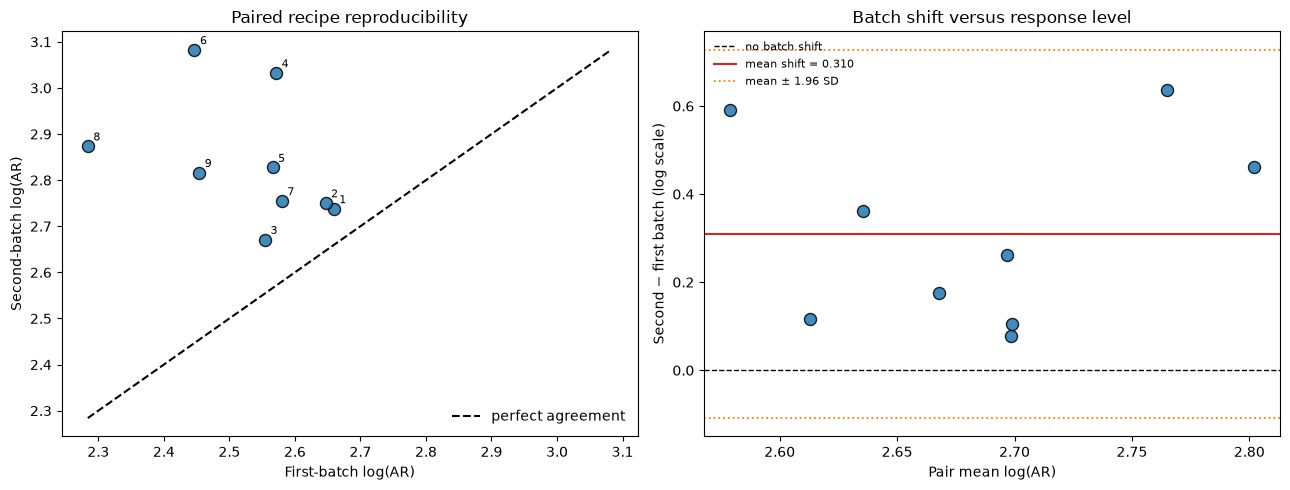

Mean paired log shift = 0.3096; 95% bootstrap CI [0.1832, 0.4465]; paired t-test p = 0.002434
Approximate geometric-mean change from first to second batch: 36.3%
The recipe-level p-value treats recipe pairs as independent. Because recipes share oven-batch pairs, this can understate uncertainty.

Batch-pair-level mean shifts (the more conservative independent units):


,batch_pair_id,n_recipes,mean_delta_log,sd_delta_log
0,B1 → B2,3,0.0999,0.0194
1,B3 → B5,3,0.4530,0.1874
2,B4 → B6,3,0.3759,0.2077


Batch-pair mean delta = 0.3096; paired-batch t-test p = 0.1019; independent batch pairs = 3


d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.25. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\

Paired-GP comparison (compare LOO scores only within the same target):


d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.5. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,Target family,Model,LOO RMSE (target units),LOO MAE (target units),Log marginal likelihood,Optimized kernel
0,Log variance,Variance GP: log(s²),1.745027,1.577393,-12.759531,0.718**2 * RBF(length_scale=0.5) + WhiteKernel...
1,Mean log(AR),Mean GP: alpha = SE² + tau²,0.074773,0.060273,-20.379525,"0.1**2 * Matern(length_scale=[0.25, 20, 11.3],..."
2,Mean log(AR),Mean GP: alpha = SE²,0.074839,0.060302,-14.783789,"0.1**2 * Matern(length_scale=[0.25, 0.629, 20]..."
3,Mean log(AR),Mean GP: WhiteKernel,0.090157,0.070526,-12.774326,0.1**2 * RBF(length_scale=0.5) + WhiteKernel(n...
4,Signed delta log(AR),Delta GP: signed delta,0.228043,0.204021,-12.772323,0.1**2 * RBF(length_scale=0.5) + WhiteKernel(n...


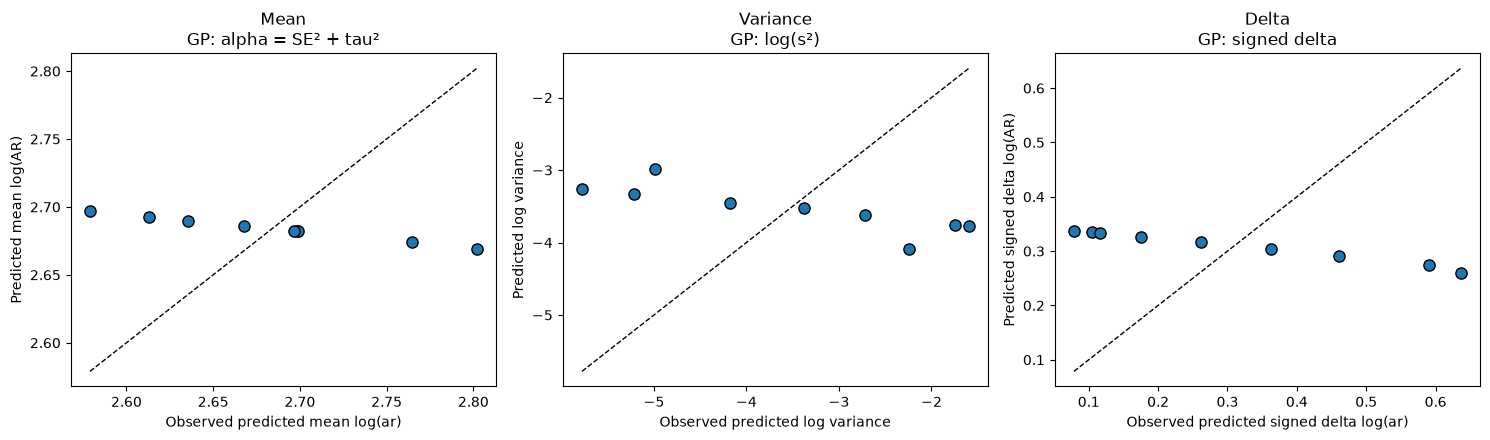

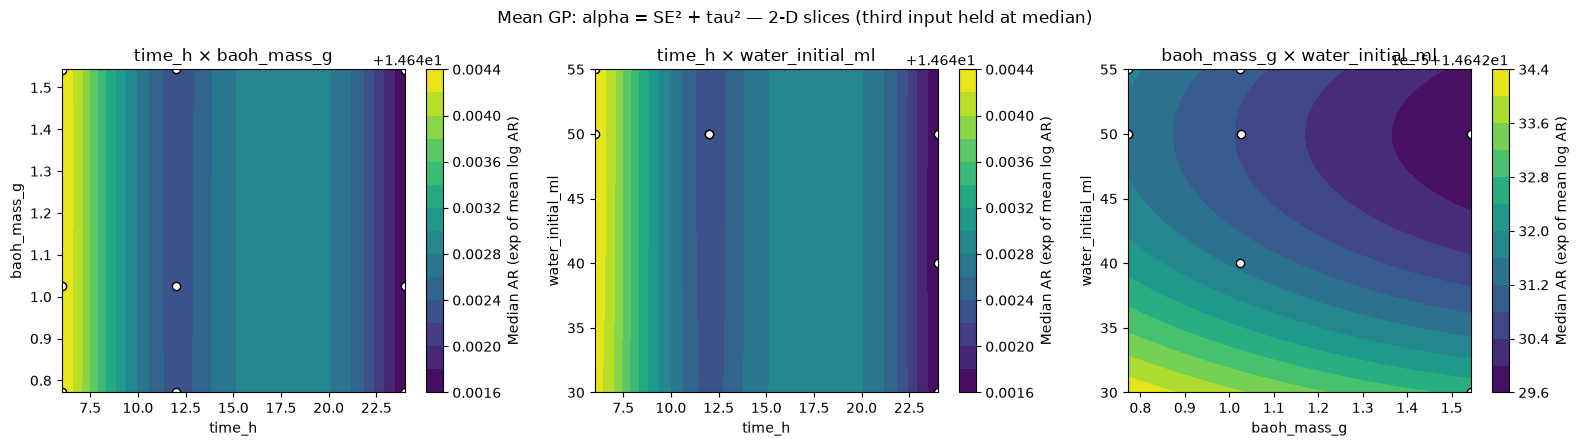

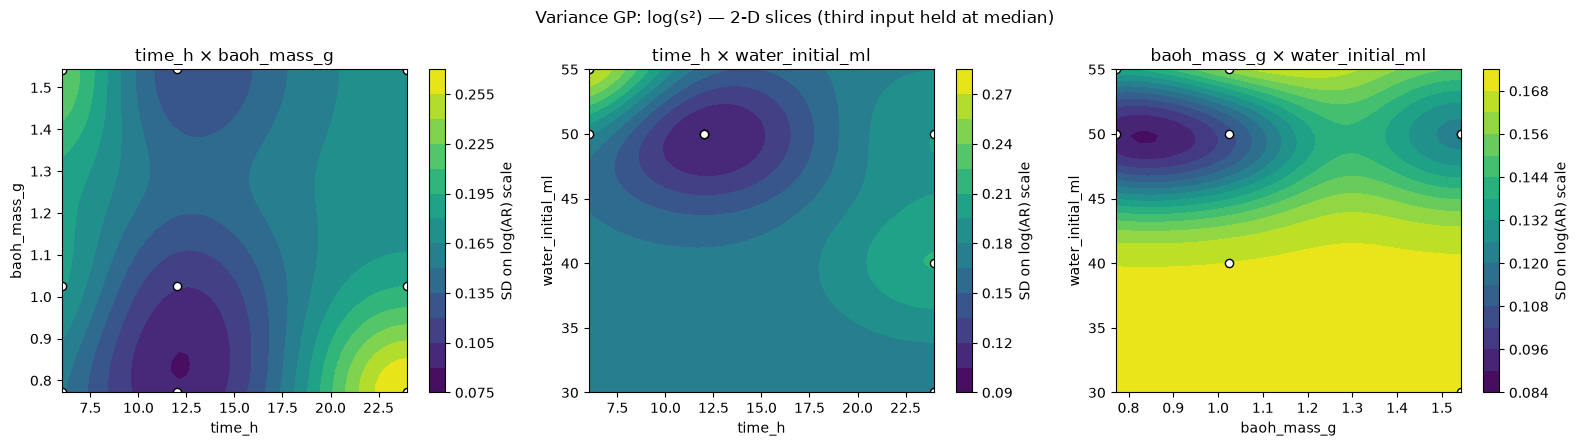

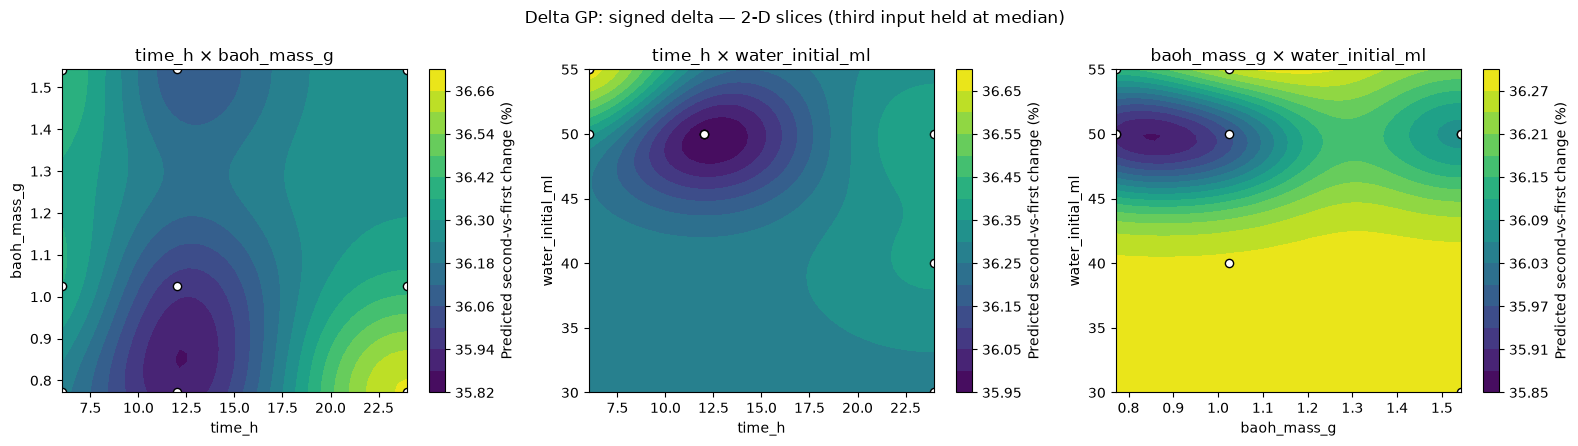


Interpretation guide:
- Mean GP: where the typical recipe response is higher/lower.
- Variance GP: where replicate-to-replicate spread is predicted to be larger.
- Delta GP: where later batches are predicted to shift up/down relative to earlier batches.
- If the variance/delta surfaces are flat and LOO skill is poor, the dataset does not support a complex noise model.


In [5]:
# ---------------------------------------------------------------------------
# A.1 Build a long, batch-level table and a paired recipe-level summary
# ---------------------------------------------------------------------------
# `recipe_id` was reconstructed from the synthesis parameters in Step 2.
# Each recipe should have been run once in an earlier batch and once in a
# later batch. We order by the numeric part of batch_id (B1 < B2 < ...).
#
# Do NOT use the S1/S2/S3 suffix to define replicate order: it is only the
# position of a sample inside a given oven batch.

import warnings
import re
from scipy.stats import ttest_1samp
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, RBF, WhiteKernel
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

def _numeric_batch_order(value):
    """Extract B12 -> 12; return NaN if a batch label has no numeric part."""
    match = re.search(r"(\d+)", str(value))
    return float(match.group(1)) if match else np.nan

pair_members = []
paired_rows = []

for recipe_id, sub in df.groupby("recipe_id", sort=True):
    sub = sub.copy()
    sub["_batch_order"] = sub["batch_id"].map(_numeric_batch_order)
    if sub["_batch_order"].isna().any():
        raise ValueError(
            f"Cannot order batches for recipe_id={recipe_id}. "
            "Check batch_id labels; expected labels such as B1, B2, ..."
        )
    sub = sub.sort_values(["_batch_order", "run_id"])

    if len(sub) < 2:
        warnings.warn(
            f"Recipe {recipe_id} has only {len(sub)} observation(s); "
            "it will be omitted from paired first-vs-second analyses."
        )
        continue
    if len(sub) > 2:
        warnings.warn(
            f"Recipe {recipe_id} has {len(sub)} observations. "
            "The paired analysis uses the first two batches only; "
            "consider extending this module for a repeated-measures model."
        )

    first = sub.iloc[0]
    second = sub.iloc[1]
    pair = {
        "recipe_id": recipe_id,
        "first_index": first.name,
        "second_index": second.name,
        "first_batch": first["batch_id"],
        "second_batch": second["batch_id"],
        "first_batch_order": first["_batch_order"],
        "second_batch_order": second["_batch_order"],
        "first_run_id": first["run_id"],
        "second_run_id": second["run_id"],
        "first_hto_mass_g": float(first["hto_mass_g"]) if "hto_mass_g" in sub else np.nan,
        "second_hto_mass_g": float(second["hto_mass_g"]) if "hto_mass_g" in sub else np.nan,
        "delta_hto_mg": (
            float((second["hto_mass_g"] - first["hto_mass_g"]) * 1000)
            if "hto_mass_g" in sub else np.nan
        ),
        "first_AR": float(first[TARGET]),
        "second_AR": float(second[TARGET]),
        "first_log_AR": float(np.log(first[TARGET])),
        "second_log_AR": float(np.log(second[TARGET])),
        "delta_AR": float(second[TARGET] - first[TARGET]),
        "delta_log": float(np.log(second[TARGET]) - np.log(first[TARGET])),
        "pair_mean_log": float((np.log(first[TARGET]) + np.log(second[TARGET])) / 2),
        "pair_mean_AR": float((first[TARGET] + second[TARGET]) / 2),
    }
    # The recipe's nominal inputs are identical by construction; use their
    # midpoint to avoid tiny floating-point weighing differences.
    for variable in OPT_VARS:
        pair[variable] = float(sub[variable].mean())
    paired_rows.append(pair)

    for order, row in enumerate([first, second], start=1):
        member = {
            "recipe_id": recipe_id,
            "pair_order": order,
            "batch_id": row["batch_id"],
            "batch_order": row["_batch_order"],
            "run_id": row["run_id"],
            "aspect_ratio": float(row[TARGET]),
            "log_aspect_ratio": float(np.log(row[TARGET])),
        }
        for variable in OPT_VARS:
            member[variable] = float(row[variable])
        pair_members.append(member)

if len(paired_rows) < 3:
    raise ValueError(
        "The paired batch analysis needs at least three recipes with two "
        "measured batch observations each."
    )

batch_level_table = pd.DataFrame(pair_members).sort_values(
    ["recipe_id", "pair_order"]
).reset_index(drop=True)

paired_summary = pd.DataFrame(paired_rows).sort_values(
    "recipe_id"
).reset_index(drop=True)

# One row per recipe pair: descriptive statistics on raw AR and log(AR).
# With the current two-batch design, n is normally 2 for every recipe.
raw_stats = (
    batch_level_table.groupby("recipe_id")["aspect_ratio"]
    .agg(mean_AR="mean", median_AR="median", sd_AR="std", n_AR="count")
    .reset_index()
)
log_stats = (
    batch_level_table.groupby("recipe_id")["log_aspect_ratio"]
    .agg(mean_log_AR="mean", median_log_AR="median",
         sd_log_AR="std", n_log_AR="count")
    .reset_index()
)
paired_summary = paired_summary.merge(raw_stats, on="recipe_id").merge(
    log_stats, on="recipe_id"
)
paired_summary["se_AR"] = paired_summary["sd_AR"] / np.sqrt(paired_summary["n_AR"])
paired_summary["se_log_AR"] = (
    paired_summary["sd_log_AR"] / np.sqrt(paired_summary["n_log_AR"])
)
paired_summary["log_variance"] = np.log(
    np.maximum(paired_summary["sd_log_AR"] ** 2, 1e-8)
)
paired_summary["delta_log_squared_half"] = np.log(
    np.maximum(paired_summary["delta_log"] ** 2 / 2, 1e-8)
)

print("Batch-level table: one row per recipe × experimental batch")
display(batch_level_table.round(4))
print("\nPaired recipe-level table: one row per recipe")
display(
    paired_summary[
        ["recipe_id", *OPT_VARS, "first_batch", "second_batch",
         "mean_AR", "median_AR", "sd_AR", "n_AR", "se_AR",
         "mean_log_AR", "median_log_AR", "sd_log_AR", "n_log_AR",
         "se_log_AR", "delta_AR", "delta_log", "delta_hto_mg"]
    ].round(4)
)
if "hto_mass_g" in df.columns:
    hto_flags = paired_summary[paired_summary["delta_hto_mg"].abs() > 5]
    if len(hto_flags):
        print(
            "\nWARNING: these paired observations differ in HTO mass by >5 mg. "
            "Their AR change may not be attributable to batch order alone:"
        )
        display(hto_flags[
            ["recipe_id", "first_batch", "second_batch",
             "first_hto_mass_g", "second_hto_mass_g", "delta_hto_mg"]
        ].round(4))

# ---------------------------------------------------------------------------
# A.2 Estimate a batch-level variance scale on the log(AR) scale
# ---------------------------------------------------------------------------
# Centre each observation by its recipe-pair mean. A batch that tends to
# produce higher AR across several recipes will have a positive offset.
# The variance of these batch offsets is used as a sensitivity estimate
# for tau^2. With only six batches, it is necessarily imprecise.

batch_level_table["within_pair_deviation_log"] = (
    batch_level_table["log_aspect_ratio"]
    - batch_level_table.groupby("recipe_id")["log_aspect_ratio"].transform("mean")
)
batch_offsets_log = (
    batch_level_table.groupby("batch_id")["within_pair_deviation_log"].mean()
)
tau2_log = float(batch_offsets_log.var(ddof=1))
print("\nEstimated batch offsets on log(AR) scale:")
display(batch_offsets_log.rename("mean_within_recipe_deviation").to_frame().round(4))
print(f"Between-batch variance estimate tau^2 (log scale): {tau2_log:.6f}")

# ---------------------------------------------------------------------------
# A.3 Look before fitting: paired plot and Bland-Altman-style plot
# ---------------------------------------------------------------------------
# Panel 1: first vs second batch. Points on y=x indicate close reproducibility.
# Panel 2: paired difference vs pair mean. A trend suggests that the size or
# direction of the batch shift depends on the underlying AR level.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

lo_pair = min(paired_summary["first_log_AR"].min(),
              paired_summary["second_log_AR"].min())
hi_pair = max(paired_summary["first_log_AR"].max(),
              paired_summary["second_log_AR"].max())
axes[0].scatter(
    paired_summary["first_log_AR"], paired_summary["second_log_AR"],
    s=75, edgecolor="black", alpha=0.85
)
axes[0].plot([lo_pair, hi_pair], [lo_pair, hi_pair], "k--", lw=1.5,
             label="perfect agreement")
for _, row in paired_summary.iterrows():
    axes[0].annotate(str(row["recipe_id"]),
                     (row["first_log_AR"], row["second_log_AR"]),
                     xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[0].set(
    xlabel="First-batch log(AR)", ylabel="Second-batch log(AR)",
    title="Paired recipe reproducibility"
)
axes[0].legend(frameon=False)

delta = paired_summary["delta_log"].to_numpy()
pair_mean = paired_summary["pair_mean_log"].to_numpy()
delta_mean = float(np.mean(delta))
delta_sd = float(np.std(delta, ddof=1))
loa_low, loa_high = delta_mean - 1.96 * delta_sd, delta_mean + 1.96 * delta_sd

axes[1].scatter(pair_mean, delta, s=75, edgecolor="black", alpha=0.85)
axes[1].axhline(0, color="black", ls="--", lw=1, label="no batch shift")
axes[1].axhline(delta_mean, color="tab:red", lw=1.5,
                label=f"mean shift = {delta_mean:.3f}")
axes[1].axhline(loa_low, color="tab:orange", ls=":", lw=1.3,
                label="mean ± 1.96 SD")
axes[1].axhline(loa_high, color="tab:orange", ls=":", lw=1.3)
axes[1].set(
    xlabel="Pair mean log(AR)", ylabel="Second − first batch (log scale)",
    title="Batch shift versus response level"
)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

# Paired test and bootstrap interval for the mean directional batch shift.
# This is a paired analysis: each recipe is its own comparison unit.
paired_test = ttest_1samp(delta, popmean=0.0)
_boot_rng = np.random.default_rng(SEED)
_boot_means = np.array([
    _boot_rng.choice(delta, size=len(delta), replace=True).mean()
    for _ in range(10000)
])
delta_ci = np.percentile(_boot_means, [2.5, 97.5])
print(
    f"Mean paired log shift = {delta_mean:.4f}; "
    f"95% bootstrap CI [{delta_ci[0]:.4f}, {delta_ci[1]:.4f}]; "
    f"paired t-test p = {paired_test.pvalue:.4g}"
)
print(
    f"Approximate geometric-mean change from first to second batch: "
    f"{100 * (np.exp(delta_mean) - 1):.1f}%"
)
print(
    "The recipe-level p-value treats recipe pairs as independent. "
    "Because recipes share oven-batch pairs, this can understate uncertainty."
)

# Primary cluster-aware check: recipes exposed to the same first/second batch
# pair share process conditions. Aggregate their deltas, then use the batch
# pair (not each recipe) as the independent unit. With only three batch pairs,
# this test has very low power; the result is a diagnostic, not a final claim.
paired_summary["batch_pair_id"] = (
    paired_summary["first_batch"].astype(str)
    + " → "
    + paired_summary["second_batch"].astype(str)
)
batch_pair_summary = (
    paired_summary.groupby("batch_pair_id")
    .agg(
        n_recipes=("delta_log", "size"),
        mean_delta_log=("delta_log", "mean"),
        sd_delta_log=("delta_log", "std")
    )
    .reset_index()
)
batch_pair_test = ttest_1samp(
    batch_pair_summary["mean_delta_log"].to_numpy(), popmean=0.0
)
print("\nBatch-pair-level mean shifts (the more conservative independent units):")
display(batch_pair_summary.round(4))
print(
    f"Batch-pair mean delta = {batch_pair_summary['mean_delta_log'].mean():.4f}; "
    f"paired-batch t-test p = {batch_pair_test.pvalue:.4g}; "
    f"independent batch pairs = {len(batch_pair_summary)}"
)

# ---------------------------------------------------------------------------
# A.4 Fit mean, variance and delta GPs; compare LOO prediction and log ML
# ---------------------------------------------------------------------------
# All inputs are standardized inside each fit. Targets are standardized
# manually so that the per-observation alpha array is in the same units as
# the GP covariance. The LOO loop refits the scaler and GP using only the
# training recipes in each fold.
#
# Mean GP target: mean(log AR) for each recipe pair.
# Variance GP target: log(sample variance of log AR) for each pair.
# Delta GP target: signed second-minus-first log(AR) difference.
#
# With two observations per pair, log(sample variance) and log(delta^2/2)
# are algebraically the same target. We retain both columns in the table
# for clarity, but do not pretend they are independent evidence.

X_pair = paired_summary[OPT_VARS].to_numpy(dtype=float)
y_mean_pair = paired_summary["mean_log_AR"].to_numpy(dtype=float)
y_var_pair = paired_summary["log_variance"].to_numpy(dtype=float)
y_delta_pair = paired_summary["delta_log"].to_numpy(dtype=float)

alpha_pair_only = np.maximum(paired_summary["se_log_AR"].to_numpy() ** 2, 1e-6)
alpha_pair_plus_tau = np.maximum(alpha_pair_only + tau2_log, 1e-6)

def _make_pair_kernel(kind, n_features):
    """Simple kernels suited to a small dataset; avoid an unnecessarily flexible GP."""
    if kind == "matern":
        return (
            ConstantKernel(1.0, (1e-2, 1e2))
            * Matern(length_scale=np.ones(n_features),
                     length_scale_bounds=(0.25, 20.0), nu=2.5)
        )
    if kind == "rbf_white":
        return (
            ConstantKernel(1.0, (1e-2, 1e2))
            * RBF(length_scale=2.0, length_scale_bounds=(0.5, 20.0))
            + WhiteKernel(noise_level=0.1,
                          noise_level_bounds=(1e-4, 1e1))
        )
    raise ValueError(f"Unknown kernel kind: {kind}")

def _fit_pair_gp(X_train, y_train, alpha_train, kernel_kind,
                 n_restarts=3, seed=SEED):
    """Fit one GP, returning scaler and target scaling for later prediction."""
    scaler = StandardScaler().fit(X_train)
    X_scaled = scaler.transform(X_train)

    y_train = np.asarray(y_train, dtype=float)
    y_mean = float(np.mean(y_train))
    y_scale = float(np.std(y_train, ddof=0))
    if not np.isfinite(y_scale) or y_scale < 1e-8:
        y_scale = 1.0
    y_scaled = (y_train - y_mean) / y_scale

    alpha_arr = np.asarray(alpha_train, dtype=float)
    if alpha_arr.ndim == 0:
        alpha_arr = np.full(len(y_train), float(alpha_arr))
    alpha_scaled = np.maximum(alpha_arr / (y_scale ** 2), 1e-8)

    gp = GaussianProcessRegressor(
        kernel=_make_pair_kernel(kernel_kind, X_train.shape[1]),
        alpha=alpha_scaled,
        normalize_y=False,
        n_restarts_optimizer=n_restarts,
        random_state=seed
    )
    gp.fit(X_scaled, y_scaled)
    return {
        "scaler": scaler, "gp": gp,
        "y_mean": y_mean, "y_scale": y_scale,
        "kernel_kind": kernel_kind
    }

def _predict_pair_gp(model, X_new, return_std=True):
    """Predict in the original target units, undoing target standardization."""
    mu, sd = model["gp"].predict(
        model["scaler"].transform(X_new), return_std=True
    )
    mu = mu * model["y_scale"] + model["y_mean"]
    sd = sd * model["y_scale"]
    return (mu, sd) if return_std else mu

def _loo_pair_gp(X_all, y_all, alpha_all, kernel_kind, seed=SEED):
    """Leave-one-recipe-out predictions; each held-out recipe is absent from fitting."""
    predictions = np.full(len(y_all), np.nan)
    for held_out in range(len(y_all)):
        train = np.arange(len(y_all)) != held_out
        model = _fit_pair_gp(
            X_all[train], y_all[train], np.asarray(alpha_all)[train],
            kernel_kind, n_restarts=1, seed=seed + held_out
        )
        predictions[held_out] = _predict_pair_gp(
            model, X_all[[held_out]], return_std=False
        )[0]
    return predictions

# Three mean-GP noise assumptions:
# 1) pair-level SE^2 only (heteroscedastic alpha);
# 2) pair-level SE^2 + tau^2 (conservative sensitivity check);
# 3) learned WhiteKernel noise instead of a per-point alpha array.
mean_gp_specs = {
    "Mean GP: alpha = SE²": (y_mean_pair, alpha_pair_only, "matern"),
    "Mean GP: alpha = SE² + tau²": (y_mean_pair, alpha_pair_plus_tau, "matern"),
    "Mean GP: WhiteKernel": (y_mean_pair, np.full(len(y_mean_pair), 1e-6), "rbf_white"),
    "Variance GP: log(s²)": (y_var_pair, np.full(len(y_var_pair), 1e-6), "rbf_white"),
    "Delta GP: signed delta": (y_delta_pair, np.full(len(y_delta_pair), 1e-6), "rbf_white"),
}

pair_gp_models = {}
pair_gp_loo = {}
pair_gp_scores = []

for model_name, (target_values, alpha_values, kernel_kind) in mean_gp_specs.items():
    loo_pred = _loo_pair_gp(
        X_pair, target_values, alpha_values, kernel_kind,
        seed=SEED + len(pair_gp_scores) * 100
    )
    final_model = _fit_pair_gp(
        X_pair, target_values, alpha_values, kernel_kind,
        n_restarts=5, seed=SEED
    )
    pair_gp_models[model_name] = final_model
    pair_gp_loo[model_name] = loo_pred
    target_family = (
        "Mean log(AR)" if model_name.startswith("Mean GP")
        else "Log variance" if model_name.startswith("Variance GP")
        else "Signed delta log(AR)"
    )
    pair_gp_scores.append({
        "Target family": target_family,
        "Model": model_name,
        "LOO RMSE (target units)": float(np.sqrt(np.mean((loo_pred - target_values) ** 2))),
        "LOO MAE (target units)": float(np.mean(np.abs(loo_pred - target_values))),
        "Log marginal likelihood": float(final_model["gp"].log_marginal_likelihood_value_),
        "Optimized kernel": str(final_model["gp"].kernel_)
    })

pair_gp_scores = pd.DataFrame(pair_gp_scores).sort_values(
    ["Target family", "LOO RMSE (target units)"]
).reset_index(drop=True)
print("Paired-GP comparison (compare LOO scores only within the same target):")
display(pair_gp_scores)

# ---------------------------------------------------------------------------
# A.5 Visualize LOO predictions for mean, variance and delta models
# ---------------------------------------------------------------------------
# LOO predictions are more informative than plotting training fits alone:
# each point is predicted without using that recipe pair in model fitting.

diagnostic_models = [
    ("Mean GP: alpha = SE² + tau²", y_mean_pair, "Predicted mean log(AR)"),
    ("Variance GP: log(s²)", y_var_pair, "Predicted log variance"),
    ("Delta GP: signed delta", y_delta_pair, "Predicted signed delta log(AR)")
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (model_name, observed, axis_label) in zip(axes, diagnostic_models):
    predicted = pair_gp_loo[model_name]
    ax.scatter(observed, predicted, s=65, edgecolor="black")
    low = min(observed.min(), predicted.min())
    high = max(observed.max(), predicted.max())
    ax.plot([low, high], [low, high], "k--", lw=1)
    ax.set_xlabel(f"Observed {axis_label.lower()}")
    ax.set_ylabel(axis_label)
    ax.set_title(model_name.replace(" GP:", "\nGP:"))
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# A.6 Plot the learned mean, variance and delta functions over parameter pairs
# ---------------------------------------------------------------------------
# These are 2-D slices through the 3-D recipe space. The third variable is
# held at its observed median. This is a visualization, not a claim that
# the other variable has no effect.

def _plot_pair_gp_slices(model_name, transform, color_label, cmap="viridis"):
    model = pair_gp_models[model_name]
    pairs = [(0, 1), (0, 2), (1, 2)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, (a, b) in zip(axes, pairs):
        c = 3 - a - b
        x_grid = np.linspace(df[OPT_VARS[a]].min(), df[OPT_VARS[a]].max(), 45)
        y_grid = np.linspace(df[OPT_VARS[b]].min(), df[OPT_VARS[b]].max(), 45)
        XX, YY = np.meshgrid(x_grid, y_grid)
        raw = np.tile(df[OPT_VARS].median().to_numpy(), (XX.size, 1))
        raw[:, a] = XX.ravel()
        raw[:, b] = YY.ravel()
        mu, _ = _predict_pair_gp(model, raw)
        ZZ = transform(mu).reshape(XX.shape)
        contour = ax.contourf(XX, YY, ZZ, levels=14, cmap=cmap)
        ax.scatter(
            paired_summary[OPT_VARS[a]], paired_summary[OPT_VARS[b]],
            c="white", edgecolor="black", s=35
        )
        ax.set_xlabel(OPT_VARS[a])
        ax.set_ylabel(OPT_VARS[b])
        ax.set_title(f"{OPT_VARS[a]} × {OPT_VARS[b]}")
        fig.colorbar(contour, ax=ax, label=color_label)
    fig.suptitle(model_name + " — 2-D slices (third input held at median)")
    plt.tight_layout()
    plt.show()

_plot_pair_gp_slices(
    "Mean GP: alpha = SE² + tau²",
    lambda z: np.exp(z),
    "Median AR (exp of mean log AR)"
)
_plot_pair_gp_slices(
    "Variance GP: log(s²)",
    lambda z: np.sqrt(np.maximum(np.exp(np.clip(z, -20, 10)), 0)),
    "SD on log(AR) scale"
)
_plot_pair_gp_slices(
    "Delta GP: signed delta",
    lambda z: 100 * (np.exp(np.clip(z, -5, 5)) - 1),
    "Predicted second-vs-first change (%)",
)

print(
    "\nInterpretation guide:\n"
    "- Mean GP: where the typical recipe response is higher/lower.\n"
    "- Variance GP: where replicate-to-replicate spread is predicted to be larger.\n"
    "- Delta GP: where later batches are predicted to shift up/down relative to earlier batches.\n"
    "- If the variance/delta surfaces are flat and LOO skill is poor, the dataset does not support a complex noise model."
)

## Step 3B — Establish the shared, recipe-grouped cross-validation benchmark

Before fitting the Bayesian-optimization surrogate or comparing acquisition functions, create the validation partitions **once**. Every candidate model (Random Forest, Matérn GP and RBF GP) reuses these exact outer and inner folds.

**Why group by recipe?** Replicate runs from the same nominal recipe must stay together. If one replicate is in training while another is held out, the model can partly recognize a recipe it has already seen and the validation score becomes optimistic.

**Why nested CV?** The outer fold estimates performance on unseen recipes. The inner folds choose hyperparameters using only the outer-training recipes. The outer test fold is not involved in tuning.

**Important distinction:** this benchmark compares predictive models. It does not, by itself, establish which acquisition function will lead to the best future laboratory outcome. Acquisition strategies are compared later on a common fitted surrogate, common candidate pool, common incumbent and common batch size. The final BO model is then refitted on all available observations; the outer-fold models are evaluation-only.

The CV benchmark below uses the same optimization inputs and target as the batch-BO workflow. It uses a standard scikit-learn GP as a transparent kernel benchmark. The operational BO model remains the custom Matérn-5/2 GP below because that model additionally represents shared oven-run offsets.

In [6]:
# Shared grouped-CV setup
# -----------------------
# Use recipe_id (computed from synthesis parameters in Step 2), not row IDs.
# All replicates of one recipe therefore stay in the same fold.

from sklearn.model_selection import GroupKFold, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, RBF, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.base import clone

# Match the BO model inputs exactly: no accidental extra predictors.
X_cv = df[OPT_VARS].astype(float).reset_index(drop=True)
y_cv = df[TARGET].astype(float).reset_index(drop=True)
groups_cv = df["recipe_id"].reset_index(drop=True)

N_OUTER = 3
N_INNER = 3
n_groups = groups_cv.nunique()
if n_groups < max(N_OUTER, N_INNER):
    raise ValueError(
        f"Nested GroupKFold needs at least {max(N_OUTER, N_INNER)} distinct recipes; "
        f"only {n_groups} were found."
    )

# Generate outer folds once; every model reuses this exact list.
outer_cv = GroupKFold(n_splits=N_OUTER)
cv_splits = list(outer_cv.split(X_cv, y_cv, groups_cv))

# Inner indices are local to each outer-training subset.
inner_cv_splits = []
fold_rows = []
for outer_no, (train_idx, test_idx) in enumerate(cv_splits, start=1):
    groups_train = groups_cv.iloc[train_idx].reset_index(drop=True)
    X_train_local = X_cv.iloc[train_idx].reset_index(drop=True)
    y_train_local = y_cv.iloc[train_idx].reset_index(drop=True)

    inner_cv = GroupKFold(n_splits=N_INNER)
    this_inner = list(inner_cv.split(X_train_local, y_train_local, groups_train))
    inner_cv_splits.append(this_inner)

    fold_rows.append({
        "Outer fold": outer_no,
        "Training recipes": sorted(groups_cv.iloc[train_idx].unique().tolist()),
        "Held-out recipes": sorted(groups_cv.iloc[test_idx].unique().tolist()),
        "Training runs": len(train_idx),
        "Held-out runs": len(test_idx),
        "Inner folds": len(this_inner)
    })

fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)

# Explicitly verify that no recipe occurs on both sides of an outer split.
for fold_no, (tr, te) in enumerate(cv_splits, start=1):
    overlap = set(groups_cv.iloc[tr]) & set(groups_cv.iloc[te])
    assert not overlap, f"Recipe leakage in outer fold {fold_no}: {overlap}"
print("Verified: outer folds are recipe-grouped and shared by every benchmark model.")

,Outer fold,Training recipes,Held-out recipes,Training runs,Held-out runs,Inner folds
0,1,"[1, 2, 4, 5, 7, 8]","[3, 6, 9]",12,6,3
1,2,"[1, 3, 4, 6, 7, 9]","[2, 5, 8]",12,6,3
2,3,"[2, 3, 5, 6, 8, 9]","[1, 4, 7]",12,6,3


Verified: outer folds are recipe-grouped and shared by every benchmark model.


### Define comparable model families and hyperparameter grids

All three models receive the same rows, features, outer folds, inner folds and primary selection metric (RMSE). Input standardization is placed inside each pipeline, so each scaler is fitted only on the training portion of a fold. This prevents information from a validation/test fold leaking into preprocessing.

Random Forest is a non-kernel reference model. Matérn and RBF are the two GP kernel alternatives. The grids are deliberately compact: with a small experimental dataset, a huge search space would be computationally expensive and could encourage overfitting.

In [7]:
# Pipelines ensure preprocessing is refitted independently inside every CV split.
# StandardScaler is important for GP lengthscales; it is harmless for RF.

cv_rf = Pipeline([
    ("scale", StandardScaler()),
    ("model", RandomForestRegressor(
        n_estimators=200,
        criterion="squared_error",
        bootstrap=True,
        random_state=SEED,
        n_jobs=1
    ))
])
rf_grid_cv = {
    "model__max_depth": [1, 2, 3, None],
    "model__min_samples_leaf": [1, 2, 3],
    "model__max_features": [0.5, 1.0]
}

# Test a shared lengthscale and ARD (one lengthscale per input).
d_cv = X_cv.shape[1]
matern_shared = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(
    length_scale=1.0, length_scale_bounds=(1e-2, 1e2), nu=2.5
) + WhiteKernel(0.1, (1e-4, 1e1))
matern_ard = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(
    length_scale=np.ones(d_cv), length_scale_bounds=(1e-2, 1e2), nu=2.5
) + WhiteKernel(0.1, (1e-4, 1e1))

rbf_shared = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(
    length_scale=1.0, length_scale_bounds=(1e-2, 1e2)
) + WhiteKernel(0.1, (1e-4, 1e1))
rbf_ard = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(
    length_scale=np.ones(d_cv), length_scale_bounds=(1e-2, 1e2)
) + WhiteKernel(0.1, (1e-4, 1e1))

def make_gp_pipeline(kernel):
    # GridSearchCV clones this pipeline for each candidate/fold.
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", GaussianProcessRegressor(
            kernel=kernel,
            alpha=1e-8,
            normalize_y=True,
            n_restarts_optimizer=3,
            random_state=SEED
        ))
    ])

model_specs = {
    "Random Forest": (cv_rf, rf_grid_cv),
    "Matérn GP": (
        make_gp_pipeline(matern_shared),
        {"model__kernel": [matern_shared, matern_ard]}
    ),
    "RBF GP": (
        make_gp_pipeline(rbf_shared),
        {"model__kernel": [rbf_shared, rbf_ard]}
    )
}

selection_scoring = "neg_root_mean_squared_error"
print("Features:", OPT_VARS)
print("Target:", TARGET)
print("Primary tuning metric: RMSE (lower is better)")
print("Candidate counts:", {
    name: len(list(ParameterGrid(grid)))
    for name, (_, grid) in model_specs.items()
})

Features: ['time_h', 'baoh_mass_g', 'water_initial_ml']
Target: aspect_ratio
Primary tuning metric: RMSE (lower is better)
Candidate counts: {'Random Forest': 24, 'Matérn GP': 2, 'RBF GP': 2}


### Run the nested benchmark

For each outer fold, GridSearchCV tunes the model using that fold's stored inner splits. It then refits the winning configuration on the complete outer-training subset and predicts the untouched outer test recipes.

The resulting out-of-fold (OOF) prediction for each run is generated by a model that did not train on that run's recipe. We report pooled OOF MAE and RMSE, as well as fold-level errors. With a small number of recipe groups, treat small score differences cautiously; fold-to-fold variability is important.

In [8]:
# Nested grouped CV for all model families
# ----------------------------------------
# Every model gets exactly the same outer and inner partitions.

benchmark_predictions = {}
benchmark_fold_results = {}
benchmark_searches = {}

for model_name, (estimator, param_grid) in model_specs.items():
    print(f"\\n===== {model_name} =====")
    oof = np.full(len(y_cv), np.nan)
    fold_records = []
    searches = []

    for fold_no, (train_idx, test_idx) in enumerate(cv_splits, start=1):
        X_train = X_cv.iloc[train_idx]
        X_test = X_cv.iloc[test_idx]
        y_train = y_cv.iloc[train_idx]
        y_test = y_cv.iloc[test_idx]

        search = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            scoring=selection_scoring,
            cv=inner_cv_splits[fold_no - 1],
            refit=True,
            return_train_score=True,
            n_jobs=-1,
            error_score="raise"
        )
        search.fit(X_train, y_train)
        pred = search.predict(X_test)
        oof[test_idx] = pred
        searches.append(search)

        fold_records.append({
            "Fold": fold_no,
            "Selected parameters": search.best_params_,
            "Inner CV RMSE": -search.best_score_,
            "Held-out MAE": mean_absolute_error(y_test, pred),
            "Held-out RMSE": np.sqrt(mean_squared_error(y_test, pred))
        })

    assert np.isfinite(oof).all(), f"Some OOF predictions are missing for {model_name}."
    benchmark_predictions[model_name] = oof
    benchmark_fold_results[model_name] = pd.DataFrame(fold_records)
    benchmark_searches[model_name] = searches

benchmark_summary = pd.DataFrame([
    {
        "Model": name,
        "OOF MAE": mean_absolute_error(y_cv, pred),
        "OOF RMSE": np.sqrt(mean_squared_error(y_cv, pred))
    }
    for name, pred in benchmark_predictions.items()
]).sort_values("OOF RMSE").reset_index(drop=True)

display(benchmark_summary.round(4))
for name, results in benchmark_fold_results.items():
    print(f"\\n{name} — outer-fold results")
    display(results.round(4))

\n===== Random Forest =====
\n===== Matérn GP =====


d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4M

\n===== RBF GP =====


d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4M

,Model,OOF MAE,OOF RMSE
0,Random Forest,2.4450,2.9476
1,RBF GP,2.3738,3.0207
2,Matérn GP,2.3730,3.0207


\nRandom Forest — outer-fold results


,Fold,Selected parameters,Inner CV RMSE,Held-out MAE,Held-out RMSE
0,1,"{'model__max_depth': 1, 'model__max_features':...",2.2648,3.1038,3.5400
1,2,"{'model__max_depth': 1, 'model__max_features':...",3.2095,2.2216,2.6682
2,3,"{'model__max_depth': 3, 'model__max_features':...",3.0824,2.0096,2.5326


\nMatérn GP — outer-fold results


,Fold,Selected parameters,Inner CV RMSE,Held-out MAE,Held-out RMSE
0,1,{'model__kernel': 1**2 * Matern(length_scale=1...,2.2781,3.0032,3.5958
1,2,{'model__kernel': 1**2 * Matern(length_scale=[...,3.1401,2.2216,2.6980
2,3,{'model__kernel': 1**2 * Matern(length_scale=[...,3.2080,1.8941,2.6766


\nRBF GP — outer-fold results


,Fold,Selected parameters,Inner CV RMSE,Held-out MAE,Held-out RMSE
0,1,{'model__kernel': 1**2 * RBF(length_scale=1) +...,2.2781,3.0057,3.5958
1,2,"{'model__kernel': 1**2 * RBF(length_scale=[1, ...",3.1401,2.2216,2.6980
2,3,"{'model__kernel': 1**2 * RBF(length_scale=[1, ...",3.2080,1.8941,2.6766


### Read the benchmark correctly — and connect it to BO

- Use **pooled OOF RMSE** as the predeclared primary predictive comparison, while also inspecting MAE and each outer fold.
- A tiny difference is not compelling evidence that one kernel is intrinsically better, especially with few independent recipes.
- This benchmark does **not** tune the custom oven-offset GP in the next step. The operational BO model explicitly includes shared oven-run offsets; the scikit-learn GP benchmark above does not. They answer related but not identical modelling questions.
- The BO stage uses one common operational surrogate and one common candidate pool when comparing acquisition strategies. Do not let each acquisition function quietly use a different model, search space, incumbent or random seed.
- After CV diagnostics, the operational GP is fitted to all observed data. CV fold models are evaluation-only and are not used to generate final experimental recommendations.

## Step 4: Train the initial Gaussian-Process surrogate

**What a GP gives us.** For any candidate recipe **x** the GP returns a *prediction* **μ(x)** and an *uncertainty* **σ(x)**. It assumes "recipes that are close to each other give similar aspect ratios".

**Our model of one measurement:**

$$ y_{i} \;=\; f(\mathbf{x}_i) \;+\; b_{\text{oven run}(i)} \;+\; \varepsilon_i $$

* $f(\mathbf{x})$: the smooth **true recipe effect** we want to optimize. Kernel: Matérn-5/2 with one lengthscale per variable (ARD), amplitude `amp2`.
* $b$: an **oven-run offset** shared by all runs of the same oven run (variance `sb2`).
* $\varepsilon$: the **leftover noise** (variance `sn2`).

Why the extra $b$ term? Without it, the oven-run effect has to be explained either as a "recipe effect" (the GP would chase it) or as white noise (the GP would give up). Modelling it separately lets the GP see $f$ through it. Note that the optimizer only ever cares about $f$, never about $b$: a *new* oven run gets a new, unknown offset.

**Preprocessing.** Inputs are rescaled to the unit cube [0, 1] (so hours, grams and mL are comparable). The target is standardized (mean 0, std 1); acquisition values below are in these standardized units and are converted back to real aspect-ratio units only for reporting.

**Fitting.** The three variances and the lengthscales are found by maximizing the **marginal likelihood** (how probable the data are under the model), with the prior bounds from Step 1.

In [9]:
# ---------- scaling helpers ----------
lo = np.array([BOUNDS[v][0] for v in OPT_VARS]); hi = np.array([BOUNDS[v][1] for v in OPT_VARS])
N_OPT = len(OPT_VARS)                       # the first N_OPT model columns are always the optimization variables

if USE_HTO_IN_MODEL:
    HTO_LO, HTO_HI = df["hto_mass_g"].min(), df["hto_mass_g"].max()
    HTO_FIXED = float(df["hto_mass_g"].median())      # value assigned to every *candidate* (HTO is never optimized)

def to_model(raw_opt):
    """raw (hours, g, mL) matrix -> model input matrix in [0,1] (+ constant HTO column if enabled)."""
    U = (np.atleast_2d(raw_opt) - lo) / (hi - lo)
    if USE_HTO_IN_MODEL:
        U = np.column_stack([U, np.full(len(U), (HTO_FIXED - HTO_LO) / (HTO_HI - HTO_LO))])
    return U

# ---------- training data (one row per run) ----------
U_obs = (df[OPT_VARS].values - lo) / (hi - lo)
X_obs = np.column_stack([U_obs, (df["hto_mass_g"].values - HTO_LO) / (HTO_HI - HTO_LO)]) if USE_HTO_IN_MODEL else U_obs
y_raw = df[TARGET].values.astype(float)
Y_MEAN, Y_SD = y_raw.mean(), y_raw.std(ddof=0)
y_obs = (y_raw - Y_MEAN) / Y_SD              # standardized target
feas_obs = df["feasible"].values             # purity-based feasibility mask of observed runs
groups_obs = df["recipe_id"].values          # which recipe each run belongs to
batch_obs = pd.factorize(df["batch_id"])[0]  # which oven run each run belongs to (integer code)

# ---------- recipe-level view (one row per distinct recipe): used for the "incumbent" ----------
rec_ids = np.unique(groups_obs)
X_rec = np.array([X_obs[groups_obs == g].mean(axis=0) for g in rec_ids])
feas_rec = np.array([feas_obs[groups_obs == g].all() for g in rec_ids])   # recipe accepted only if all its runs are pure enough

# ---------- the GP, written out ----------
def matern52(A, B, ls, amp2):
    """Matern-5/2 kernel with one lengthscale per input (ARD):  amp2 * (1 + sqrt5 r + 5 r^2 / 3) * exp(-sqrt5 r),
    where r is the Euclidean distance after dividing each coordinate by its lengthscale."""
    r = np.sqrt((((A[:, None, :] - B[None, :, :]) / ls) ** 2).sum(-1))
    s = np.sqrt(5.0) * r
    return amp2 * (1.0 + s + s ** 2 / 3.0) * np.exp(-s)

def train_cov(H, X, batch):
    """Covariance of the measured values: smooth recipe effect + shared oven-run offset + independent noise."""
    same_oven = (batch[:, None] == batch[None, :]).astype(float)
    return matern52(X, X, H["ls"], H["amp2"]) + H["sb2"] * same_oven + (H["sn2"] + 1e-8) * np.eye(len(X))

def unpack(theta, d, null=False):
    """theta = log of [amp2, ls_1..ls_d, sb2, sn2]. null=True switches the smooth recipe effect OFF (amp2 ~ 0)."""
    return {"amp2": 1e-8 if null else float(np.exp(theta[0])), "ls": np.exp(theta[1:1 + d]),
            "sb2": float(np.exp(theta[1 + d])), "sn2": float(np.exp(theta[2 + d]))}

def neg_log_marginal_likelihood(theta, X, y, batch, null=False):
    H = unpack(theta, X.shape[1], null)
    try:
        L = cholesky(train_cov(H, X, batch), lower=True)
    except Exception:
        return 1e10                                           # not positive definite -> reject this hyperparameter set
    a = cho_solve((L, True), y)
    return 0.5 * y @ a + np.log(np.diag(L)).sum() + 0.5 * len(y) * np.log(2 * np.pi)

def fit_gp(X, y, batch, n_restarts=40, null=False, seed=SEED):
    """Maximize the marginal likelihood from many random starts (the surface has several local optima)."""
    d = X.shape[1]
    bnds = ([tuple(np.log(AMP2_BOUNDS))] + [tuple(np.log(LS_BOUNDS))] * d
            + [tuple(np.log(SB2_BOUNDS)), tuple(np.log(SN2_BOUNDS))])
    r = np.random.default_rng(seed)
    best = None
    for _ in range(n_restarts):
        res = minimize(neg_log_marginal_likelihood, [r.uniform(a, b) for a, b in bnds], args=(X, y, batch, null),
                       method="L-BFGS-B", bounds=bnds)
        if best is None or res.fun < best.fun: best = res
    H = unpack(best.x, d, null); H["nll"] = float(best.fun)
    return H

def posterior(H, X, y, batch, Xs, full_cov=False):
    """Posterior of the LATENT function f at points Xs (no oven offset, no noise):
         mean = K*  (K + offsets + noise)^-1 y
         cov  = K** - K*  (K + offsets + noise)^-1  K*^T
    full_cov=False returns only variances (cheap for the 38k-candidate pool)."""
    cf = cho_factor(train_cov(H, X, batch), lower=True)
    Ks = matern52(Xs, X, H["ls"], H["amp2"])
    mu = Ks @ cho_solve(cf, y)
    V = cho_solve(cf, Ks.T)
    if full_cov:
        return mu, matern52(Xs, Xs, H["ls"], H["amp2"]) - Ks @ V
    return mu, np.maximum(H["amp2"] - np.einsum("ij,ji->i", Ks, V), 1e-12)

H = fit_gp(X_obs, y_obs, batch_obs)

def predict(Xs, X=None, y=None, batch=None, full_cov=False):
    """Posterior with the FITTED hyperparameters. By default conditioned on the real data; pass (X, y, batch) to
    condition on real data + fantasy points instead (Prong 2)."""
    return posterior(H, X_obs if X is None else X, y_obs if y is None else y,
                     batch_obs if batch is None else batch, Xs, full_cov)

# ---------- sanity check of our kernel against scikit-learn's ----------
A_, B_ = np.random.default_rng(0).random((6, X_obs.shape[1])), np.random.default_rng(1).random((5, X_obs.shape[1]))
sk = ConstantKernel(H["amp2"], "fixed") * Matern(length_scale=H["ls"], nu=2.5, length_scale_bounds="fixed")
print("max |our kernel - sklearn kernel| =", np.abs(matern52(A_, B_, H["ls"], H["amp2"]) - sk(A_, B_)).max().round(10), "(should be ~0)")

# ---------- what did the fit say? ----------
tot = H["amp2"] + H["sb2"] + H["sn2"]
print("\nVariance decomposition (share of total):")
print(f"  smooth recipe effect f : {100*H['amp2']/tot:5.1f}%   (amp2 = {H['amp2']:.2f})")
print(f"  oven-run offset b      : {100*H['sb2']/tot:5.1f}%   (sb2  = {H['sb2']:.2f})")
print(f"  leftover noise         : {100*H['sn2']/tot:5.1f}%   (sn2  = {H['sn2']:.2f})")
names_model = OPT_VARS + (["hto"] if USE_HTO_IN_MODEL else [])
print("Lengthscales (unit cube; long = that variable barely matters):", {n: round(float(v), 2) for n, v in zip(names_model, H["ls"])})
for n, v in zip(names_model, H["ls"]):
    if v >= LS_BOUNDS[1] * 0.99: print(f"  note: '{n}' is at the upper lengthscale bound -> the data see no effect of this variable")
if H["amp2"] <= AMP2_BOUNDS[0] * 1.01:
    print("  note: the recipe-effect amplitude sits on its LOWER bound -> see the evidence test below.")

max |our kernel - sklearn kernel| = 0.0 (should be ~0)

Variance decomposition (share of total):
  smooth recipe effect f :   8.6%   (amp2 = 0.10)
  oven-run offset b      :  71.6%   (sb2  = 0.83)
  leftover noise         :  19.7%   (sn2  = 0.23)
Lengthscales (unit cube; long = that variable barely matters): {'time_h': 0.5, 'baoh_mass_g': 5.0, 'water_initial_ml': 5.0}
  note: 'baoh_mass_g' is at the upper lengthscale bound -> the data see no effect of this variable
  note: 'water_initial_ml' is at the upper lengthscale bound -> the data see no effect of this variable
  note: the recipe-effect amplitude sits on its LOWER bound -> see the evidence test below.


**Is there any evidence of a recipe effect at all?** Compare the fitted model with a **null model** in which the smooth recipe effect $f$ is switched off (only oven-run offsets + noise). The gain in log-likelihood is the evidence for $f$ in the data. Roughly: a gain below ~2 nats means "the data cannot tell the difference".

This matters because a GP will happily return *some* surface; the question is whether the data support it. If there is no evidence, the proposals of every strategy are driven mostly by the **prior** (and by where the data are missing), i.e. they are exploration, and the *design of the experiments* (how runs are spread over oven runs) is what will make the next round informative.

In [10]:
H_null = fit_gp(X_obs, y_obs, batch_obs, null=True)
gain = H_null["nll"] - H["nll"]
print(f"log-likelihood gain from including a smooth recipe effect: {gain:.2f} nats")
if gain < 2:
    print("-> Weak/no evidence for a recipe effect in this dataset once oven-run offsets are accounted for.")
    print("   The surrogate surface below is therefore mostly prior; treat the batches as exploration and do not over-read the predictions.")
else:
    print("-> The data support a smooth recipe effect.")

log-likelihood gain from including a smooth recipe effect: -0.27 nats
-> Weak/no evidence for a recipe effect in this dataset once oven-run offsets are accounted for.
   The surrogate surface below is therefore mostly prior; treat the batches as exploration and do not over-read the predictions.


**Leave-one-recipe-out cross-validation.** We hide *both replicates* of one recipe, refit the GP on the rest, predict the hidden recipe, and repeat for all recipes. Splitting by recipe (not by row) is essential: if one replicate stayed in training the model would "cheat". The baseline is "always predict the training mean". The target here is the raw measurement (which still contains the unpredictable oven offset), so RMSE values stay high even for a good model.

In [11]:
def loo_recipe_cv(X, y, batch, groups, n_restarts=10):
    pred, base = np.zeros_like(y), np.zeros_like(y)
    for g in np.unique(groups):
        te = groups == g
        Hg = fit_gp(X[~te], y[~te], batch[~te], n_restarts=n_restarts)
        pred[te], _ = posterior(Hg, X[~te], y[~te], batch[~te], X[te])
        base[te] = y[~te].mean()
    return pred, base

pred_cv, base_cv = loo_recipe_cv(X_obs, y_obs, batch_obs, groups_obs)
rmse_gp   = np.sqrt(np.mean((pred_cv - y_obs) ** 2)) * Y_SD
rmse_base = np.sqrt(np.mean((base_cv - y_obs) ** 2)) * Y_SD
print(f"Leave-one-recipe-out RMSE: GP = {rmse_gp:.2f}   |  'predict the mean' baseline = {rmse_base:.2f}   (aspect-ratio units)")
print("GP clearly better than the baseline." if rmse_gp < 0.9 * rmse_base else
      "GP is not clearly better than the baseline: the data are too noisy/sparse to learn the response surface yet. "
      "Batch strategies still produce proposals, but treat them as exploration.")

Leave-one-recipe-out RMSE: GP = 3.00   |  'predict the mean' baseline = 3.05   (aspect-ratio units)
GP is not clearly better than the baseline: the data are too noisy/sparse to learn the response surface yet. Batch strategies still produce proposals, but treat them as exploration.


**What did the GP learn?** Predicted aspect ratio (colors) over time × Ba(OH)₂ mass at three initial-water volumes (low / middle / high). Dots are the observed runs with water within ±6 mL of the slice.

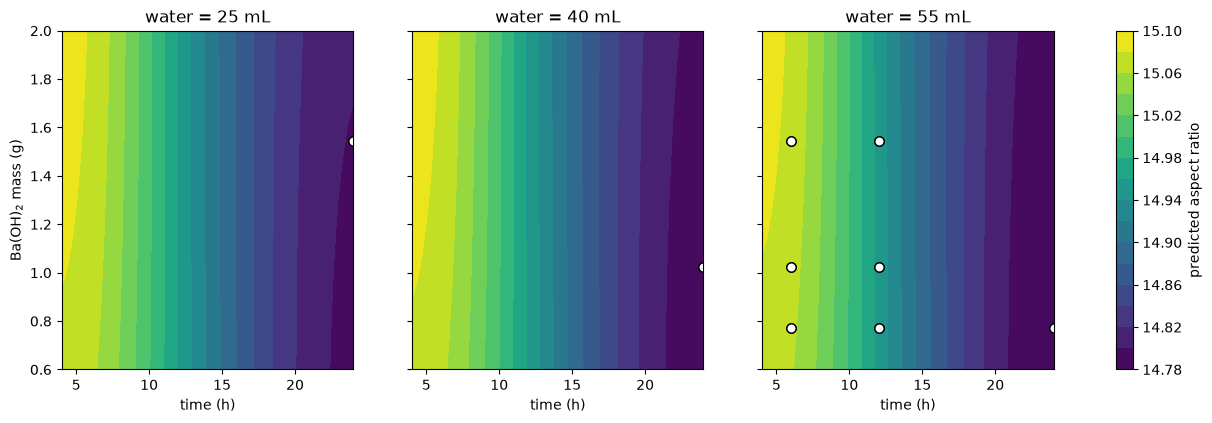

Predicted aspect ratio spans only 0.30 units across this slice: compare with the replicate scatter in Step 3. A nearly flat surface = the model has found little structure to exploit.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
gt, gb = np.linspace(lo[0], hi[0], 60), np.linspace(lo[1], hi[1], 60)
Tm, Bm = np.meshgrid(gt, gb)
for ax, w in zip(axes, np.linspace(lo[2], hi[2], 3)):
    raw = np.column_stack([Tm.ravel(), Bm.ravel(), np.full(Tm.size, w)])
    mu_s, _ = predict(to_model(raw))
    cs = ax.contourf(Tm, Bm, (mu_s * Y_SD + Y_MEAN).reshape(Tm.shape), levels=15, cmap="viridis")
    near = (df["water_initial_ml"] - w).abs() <= 6
    ax.scatter(df.loc[near, "time_h"], df.loc[near, "baoh_mass_g"], c="white", edgecolor="k", s=45)
    ax.set_title(f"water = {w:.0f} mL"); ax.set_xlabel("time (h)")
axes[0].set_ylabel("Ba(OH)$_2$ mass (g)")
fig.colorbar(cs, ax=axes, label="predicted aspect ratio"); plt.show()
mu_all, _ = predict(to_model(np.column_stack([np.repeat(gt, 5), np.tile(np.linspace(lo[1], hi[1], 5), len(gt)), np.full(len(gt) * 5, lo[2] + 0.5 * (hi[2] - lo[2]))])))
print(f"Predicted aspect ratio spans only {np.ptp(mu_all) * Y_SD:.2f} units across this slice: compare with the replicate scatter in Step 3. "
      "A nearly flat surface = the model has found little structure to exploit.")

## Step 5: Common candidate pool

All strategies must choose from the **same list of possible experiments**, otherwise differences in the results could come from the list, not from the strategy. We build a regular grid over the bounds (using the lab-realistic STEP sizes), apply the lab constraints, and drop candidates that are essentially repeats of recipes already run.

The same `gp` (fitted above) is the common starting model for every strategy.

In [13]:
axes_vals = [np.round(np.arange(BOUNDS[v][0], BOUNDS[v][1] + STEP[v] / 2, STEP[v]), 4) for v in OPT_VARS]
grid = np.meshgrid(*axes_vals, indexing="ij")
pool_raw = np.column_stack([g.ravel() for g in grid])               # every combination of the three variables
pool_df = pd.DataFrame(pool_raw, columns=OPT_VARS)

keep = np.asarray(lab_constraints(pool_df), dtype=bool)             # practical lab constraints
if ALLOWED_TIMES is not None:                                       # e.g. a single oven run can only use one time
    keep &= pool_df["time_h"].isin(ALLOWED_TIMES).values
d_to_obs = cdist((pool_raw - lo) / (hi - lo), U_obs).min(axis=1)    # distance to the closest already-run experiment
keep &= d_to_obs >= EXCLUDE_RADIUS

pool_raw = pool_raw[keep]; pool_df = pool_df[keep].reset_index(drop=True)
U_pool = (pool_raw - lo) / (hi - lo)       # unit-cube coordinates of the optimization variables (used for distances)
X_pool = to_model(pool_raw)                # model inputs (same as U_pool unless HTO is included)
print(f"Candidate pool: {len(pool_df):,} recipes "
      f"({' x '.join(str(len(a)) for a in axes_vals)} grid, minus lab constraints and repeats of tested recipes)")

Candidate pool: 91,500 recipes (21 x 141 x 31 grid, minus lab constraints and repeats of tested recipes)


### Shared tools: acquisition functions and the "incumbent"

An **acquisition function** turns (μ, σ) into one number that says *how attractive is it to run this experiment*:
* **UCB** = μ + κσ: optimism in the face of uncertainty.
* **EI** (expected improvement) = expected amount by which the experiment beats the current best.
* **PI** = probability of beating the current best (ignores *by how much*).

**The incumbent (`BEST_F`).** EI/PI need "the current best". Our measurements are noisy (replicates differ by several units!), so the *largest raw measurement* is biased upward by luck. A more honest incumbent is the **largest posterior mean among the observed (purity-acceptable) recipes**. We use that and keep it fixed for all strategies so the comparison is fair.

All acquisition values use σ of the **latent function** (what the recipe truly yields on average), not the noisy predictive σ.

In [14]:
def acq_ucb(mu, sd, best_f): return mu + KAPPA * sd
def acq_ei(mu, sd, best_f):
    z = (mu - best_f - XI) / sd
    return (mu - best_f - XI) * norm.cdf(z) + sd * norm.pdf(z)
def acq_pi(mu, sd, best_f): return norm.cdf((mu - best_f - XI) / sd)
ACQS = {"UCB": acq_ucb, "EI": acq_ei, "PI": acq_pi}
ACQ = ACQS[ACQ_NAME]

mu_at_rec, _ = predict(X_rec)
BEST_F    = mu_at_rec[feas_rec].max()     # robust incumbent: best posterior mean of f among accepted recipes (free of oven offsets)
Y_OBS_MAX = y_obs[feas_obs].max()         # classical incumbent (largest raw measurement, oven offset included), only used by plain q-EI

# GP predictions over the whole pool (real data only): used by Prong 1 and by the reporting tables
mu_pool, var_pool = predict(X_pool)
sd_pool = np.sqrt(var_pool)
print(f"Incumbent (standardized) = {BEST_F:.3f}  ->  {BEST_F*Y_SD+Y_MEAN:.2f} aspect-ratio units "
      f"(largest raw measurement: {y_raw[feas_obs].max():.2f})")

Incumbent (standardized) = 0.048  ->  15.07 aspect-ratio units (largest raw measurement: 21.82)


## Step 6 (Prong 1): acquisition ranking + minimum-distance selection

**Naive idea:** score every candidate with the acquisition function and take the top q. **Problem:** the top scores usually sit next to each other (they are all near the same promising spot), so we would run q nearly identical experiments and learn almost nothing extra.

**Fix:** walk down the ranked list, and accept a candidate only if it is at least `D_MIN` (normalized distance) away from every candidate already accepted. This is cheap and robust, but it is *geometric*: it does not know how the *outcomes* of nearby experiments are correlated.

In [15]:
def min_distance_batch(scores, U, q, d_min):
    """Greedy: go through candidates by decreasing score; keep one only if >= d_min from all kept ones."""
    chosen = []
    for j in np.argsort(-scores):
        if all(np.linalg.norm(U[j] - U[k]) >= d_min for k in chosen):
            chosen.append(j)
            if len(chosen) == q: break
    if len(chosen) < q:
        print(f"WARNING: only {len(chosen)} candidates satisfy D_MIN={d_min}; lower D_MIN or widen the bounds.")
    return np.array(chosen)

scores_p1 = ACQ(mu_pool, sd_pool, BEST_F)
batch_p1 = min_distance_batch(scores_p1, U_pool, Q, D_MIN)
print(f"Prong 1 ({ACQ_NAME} + min distance {D_MIN}) picked pool rows: {batch_p1}")

Prong 1 (EI + min distance 0.25) picked pool rows: [4340 4348 4356 3255]


## Step 7 (Prong 2): sequential selection with fantasy observations

**Idea.** Pick the best candidate with the acquisition function. We cannot run it yet, but we can **pretend** we did and got a made-up result (a *fantasy*). Add that fantasy to a *temporary copy* of the data, update the GP (same hyperparameters, new conditioning), recompute the acquisition and pick the next candidate. Repeat until q are chosen. The made-up point shrinks the GP's uncertainty (and sometimes the mean) around the chosen recipe, so the next pick is pushed elsewhere.

Three ways to invent the result:
* **Kriging believer (KB):** use the GP's own prediction μ(x). Neutral: it changes the *uncertainty* only, not the mean.
* **Constant liar, mean (CL-mean):** every chosen point is "observed" at the average observed value. Mildly pessimistic near good regions.
* **Constant liar, low (CL-low):** every chosen point is "observed" at the *worst* observed value. Strongly discourages neighbours, i.e. the most exploratory/spread-out variant.

**Important:** fantasies live only inside this function. `X_obs`/`y_obs` are never modified, and fantasies are never written to any dataset.

In [16]:
def sequential_batch(strategy, q, acq_fn=ACQ):
    """strategy in {'KB','CL_mean','CL_low'}; returns the chosen pool rows in selection order."""
    n_real = len(X_obs)
    X_aug, y_aug, b_aug = X_obs.copy(), y_obs.copy(), batch_obs.copy()   # TEMPORARY copies: real data stay untouched
    chosen = []
    for _ in range(q):
        mu, var = predict(X_pool, X_aug, y_aug, b_aug) # GP conditioned on real + fantasy points
        score = acq_fn(mu, np.sqrt(var), BEST_F)       # supplied acquisition; same incumbent for fair comparison
        score[chosen] = -np.inf                        # never pick the same candidate twice
        j = int(np.argmax(score)); chosen.append(j)
        # --- invent the fantasy outcome (standardized units) ---
        if   strategy == "KB":      lie = mu[j]
        elif strategy == "CL_mean": lie = y_obs.mean()
        elif strategy == "CL_low":  lie = y_obs.min()
        else: raise ValueError(strategy)
        X_aug = np.vstack([X_aug, X_pool[j]]); y_aug = np.append(y_aug, lie)
        b_aug = np.append(b_aug, b_aug.max() + 1)       # the fantasy gets an oven run of its own (no shared offset)
    assert len(X_obs) == n_real and len(y_obs) == n_real   # fantasies were never added to the real data
    return np.array(chosen)

batch_kb  = sequential_batch("KB", Q)
batch_clm = sequential_batch("CL_mean", Q)
batch_cll = sequential_batch("CL_low", Q)
print("Kriging believer :", batch_kb)
print("Constant liar mean:", batch_clm)
print("Constant liar low :", batch_cll)

Kriging believer : [4340 4309 4341 4370]
Constant liar mean: [4340 4309 4370 4278]
Constant liar low : [ 4340 91469    30 47894]


### Compare UCB, EI and PI on the same surrogate and candidate pool

The next cell performs a controlled acquisition-function comparison for Prongs 1 and 2. Each acquisition function receives the **same** posterior predictions, incumbent, candidate pool, batch size and minimum-distance rule. The only changed element is the acquisition formula. The joint q-EI and q-NEI strategies remain separate Prong-3 methods and are retained in the overall comparison.

In [17]:
# Acquisition-function sweep for Prongs 1 and 2
# ----------------------------------------------
# This is the apples-to-apples comparison:
#   same fitted GP, same X_pool, same BEST_F, same Q and same D_MIN.
# Only the acquisition function changes.

BATCHES_P1_P2 = {}
for acq_name, acq_fn in ACQS.items():
    # Prong 1: rank candidates once, then enforce the same minimum separation.
    scores = acq_fn(mu_pool, sd_pool, BEST_F)
    BATCHES_P1_P2[f"P1 {acq_name} + min-distance"] = min_distance_batch(
        scores, U_pool, Q, D_MIN
    )

    # Prong 2: same fantasy strategy, but substitute the acquisition formula.
    for fantasy_name in ["KB", "CL_mean", "CL_low"]:
        selected = sequential_batch(fantasy_name, Q, acq_fn=acq_fn)
        pretty_name = {
            "KB": "Kriging believer",
            "CL_mean": "Constant liar mean",
            "CL_low": "Constant liar low"
        }[fantasy_name]
        BATCHES_P1_P2[f"P2 {pretty_name} — {acq_name}"] = selected

print(f"Generated {len(BATCHES_P1_P2)} Prong-1/2 batches "
      f"({len(ACQS)} acquisition functions × 4 selection variants).")

Generated 12 Prong-1/2 batches (3 acquisition functions × 4 selection variants).


## Step 8 (Prong 3): joint batch BO with q-EI and q-NEI

**Joint view.** Prong 1 scores candidates one by one; Prong 2 scores them one after another with pretend data. Prong 3 evaluates a **whole batch as one object**.

**q-EI via Monte Carlo (the "sampling" idea).**
1. Draw many plausible versions of the true response surface from the GP's **joint** posterior over the batch (this keeps the correlations: if two recipes are close, they go up or down *together* in each sample).
2. In each sample, the batch's result is the **best** of its q recipes. The improvement is `max(0, best of batch − incumbent)`.
3. Average over samples: that is q-EI.

Two nearby recipes are highly correlated, so they rarely beat each other by much: adding the second contributes little, and the criterion automatically prefers a spread-out batch, with no distance threshold needed.

**q-NEI (noisy EI).** Our incumbent is itself uncertain (noisy measurements). q-NEI draws the incumbent **inside each sample too**: it uses the best *sampled* value of $f$ among the already-tested recipes, instead of one fixed number. (Plain q-EI below uses the largest raw measurement, which still contains the lucky oven offset, so expect it to be hard to beat.) This is the version I recommend with replicate scatter this large. (BoTorch's `qLogNoisyExpectedImprovement` is the numerically stabilized form of the same idea; it is not needed at this tiny scale.)

**Optimizing over batches.** Searching all combinations of q out of ~38,000 candidates is impossible, so we use **sequential greedy** maximization (as BoTorch does): add the candidate that most increases the *joint* value, given those already in the batch. Unlike Prong 2, the earlier picks are **not** treated as fantasies with fixed values: each Monte-Carlo sample carries the uncertainty. To keep it fast we search a **shortlist** (top-EI candidates + random ones) and reuse the same random numbers for every evaluation (common random numbers) so comparisons are stable.

In [18]:
def safe_cholesky(cov, base_jitter=1e-6):
    """Cholesky of a covariance that may be numerically singular (near-duplicate points): add growing jitter."""
    jit = base_jitter * np.mean(np.diag(cov))
    for _ in range(8):
        try:
            return cholesky(cov + jit * np.eye(len(cov)), lower=True)
        except Exception:
            jit *= 10
    raise np.linalg.LinAlgError("covariance not positive definite even with jitter")

def joint_samples(X_extra, n_samples, seed):
    """Joint posterior samples of the latent function f at [observed recipes ; X_extra]. Shape (n_rec+len(X_extra), S)."""
    Xj = np.vstack([X_rec, X_extra])
    mu, cov = predict(Xj, full_cov=True)
    L = safe_cholesky(cov)
    Z = np.random.default_rng(seed).standard_normal((len(Xj), n_samples))
    return mu[:, None] + L @ Z

def incumbent_samples(F, noisy):
    """Incumbent per Monte-Carlo sample. noisy=True (q-NEI): best sampled value among accepted observed recipes.
       noisy=False (plain q-EI): one fixed number = best raw measurement."""
    n = len(X_rec)
    return F[:n][feas_rec].max(axis=0) if noisy else np.full(F.shape[1], Y_OBS_MAX)

def greedy_joint_batch(q, noisy, n_samples=N_MC_OPT, seed=SEED):
    # ---- shortlist: promising (top EI) + random (so the batch can also pick exploratory spots) ----
    ei = acq_ei(mu_pool, sd_pool, BEST_F)
    top = np.argsort(-ei)[:SHORT_TOP]
    rest = np.setdiff1d(np.arange(len(X_pool)), top)
    rnd = np.random.default_rng(seed).choice(rest, size=min(SHORT_RAND, len(rest)), replace=False)
    short = np.concatenate([top, rnd])
    # ---- ONE set of joint samples for the whole shortlist (common random numbers) ----
    F = joint_samples(X_pool[short], n_samples, seed)
    inc = incumbent_samples(F, noisy)
    Fc = F[len(X_rec):]                                   # (M, S) sampled values of every shortlisted candidate
    best_in_batch = np.full(n_samples, -np.inf)
    chosen = []
    for _ in range(q):
        cur = np.maximum(best_in_batch[None, :], Fc)      # batch best if we add candidate m (M, S)
        gain = np.maximum(cur - inc[None, :], 0).mean(axis=1)   # Monte-Carlo (q)EI of "batch so far + m"
        gain[chosen] = -np.inf
        m = int(np.argmax(gain)); chosen.append(m)
        best_in_batch = cur[m]
    return short[np.array(chosen)]

batch_qei  = greedy_joint_batch(Q, noisy=False)
batch_qnei = greedy_joint_batch(Q, noisy=True)
print("q-EI  (fixed incumbent)   :", batch_qei)
print("q-NEI (noisy incumbent)   :", batch_qnei)

q-EI  (fixed incumbent)   : [4340 4309 4341 4278]
q-NEI (noisy incumbent)   : [ 4340 65162   712 22083]


## Step 9 (optional benchmark): maximum-entropy batch selection

**Idea.** Ignore the objective completely. Choose the batch whose predicted outcomes are *jointly* the most uncertain, i.e. that maximizes the Gaussian entropy

$$H(X_B)=\tfrac12\log\!\big((2\pi e)^q\,\det K_B\big),$$

where $K_B$ is the GP predictive covariance of the batch (we add the leftover-noise variance on the diagonal because we will observe noisy measurements). Maximizing $\det K_B$ favours recipes that are individually uncertain **and** mutually uncorrelated (far apart): the batch teaches us the most about the whole response surface.

**Practical trick.** A GP's variance does not depend on the observed values, only on *where* we measured. The greedy log-det maximizer is therefore: pick the point with the largest variance, add it as a (dummy) data point, recompute variances, repeat.

**Expect:** points pushed toward the *corners/edges* of the box (that is where the GP knows least). It is an information-seeking benchmark, not a way to find a high aspect ratio.

In [19]:
def max_entropy_batch(q):
    X_aug, y_aug, b_aug = X_obs.copy(), y_obs.copy(), batch_obs.copy()
    chosen = []
    for _ in range(q):
        _, var = predict(X_pool, X_aug, y_aug, b_aug)  # variance only depends on locations, so the dummy y below is irrelevant
        var[chosen] = -np.inf
        j = int(np.argmax(var)); chosen.append(j)
        X_aug = np.vstack([X_aug, X_pool[j]]); y_aug = np.append(y_aug, 0.0); b_aug = np.append(b_aug, b_aug.max() + 1)
    return np.array(chosen)

batch_ent = max_entropy_batch(Q)
print("Max-entropy:", batch_ent)

Max-entropy: [91499  4340 65347     0]


## Step 10: Compare the proposed batches

Every batch is now scored with the **same yardsticks** (so no strategy is judged by its own criterion alone):

| Metric | Meaning | Higher is… |
|---|---|---|
| `qNEI` / `qEI` | Expected improvement of the whole batch over the incumbent, in aspect-ratio units (independent Monte-Carlo samples, not the ones used for optimizing) | better for finding high aspect ratio |
| `logdet` | Joint entropy criterion (up to constants) | more informative |
| `min_dist`, `mean_dist` | Normalized spread between the batch's recipes | more diverse |
| `fill` | Average distance from random recipes to the nearest tested-or-proposed recipe | **lower** = better coverage of the space |
| `mean_mu`, `mean_sd` | Average predicted aspect ratio / uncertainty of the batch | exploitation vs exploration |

**Remember: purity is not predicted.** A recipe with a high predicted aspect ratio is only a *candidate*; purity must still be measured (XRD).

In [20]:
# Combine the controlled Prong-1/2 acquisition sweep with Prong-3 and entropy.
# q-EI and q-NEI are inherently joint-batch acquisition methods, not UCB/EI/PI variants.
BATCHES = {
    **BATCHES_P1_P2,
    "P3 q-EI": batch_qei,
    "P3 q-NEI": batch_qnei,
    "Entropy (max-entropy)": batch_ent,
}


## Step 10A — Train and compare separate first-batch and second-batch surrogates

This module intentionally fits **two independent operational GPs**:
- **First observations:** the earlier batch result for every recipe group;
- **Second observations:** the later batch result for the same recipe groups.

Each training set therefore contains one observation per recipe, rather than mixing first and second observations. We first rerun the nested RF/Matérn/RBF model benchmark separately on each subset, using the same outer and inner GroupKFold indices for every model and both subsets. We then fit the operational custom Matérn-5/2 GP with an oven-batch random effect to each subset and compare its fitted hyperparameters and BO proposals. The fitted hyperparameters are allowed to differ because that difference is part of what we want to study.

**Why this split is useful:** it shows whether the response surface, uncertainty, learned lengthscales, and proposed experiments change when the data come from the later batch. It does not by itself prove that batch number caused the change: batch order may be confounded with other procedural or instrument changes.

The surfaces below show the predicted *median* AR, obtained by exponentiating the GP prediction on log(AR). For each parameter pair, the third parameter is held at the median of the observed design. Both columns use the same color scale within a row, so visual differences are directly comparable.

The split-specific batch comparison reruns Prong 1 (acquisition ranking + minimum distance), Prong 2 (Kriging believer and Constant liar), Prong 3 (joint q-EI/q-NEI), and maximum entropy **separately** for each fitted operational GP. These are model-based proposals only; their predicted scores are not experimental validation.

First-batch training set:  9 recipe observations
Second-batch training set: 9 recipe observations


,recipe_id,first batch,first AR,second batch,second AR
0,1,B1,14.2854,B2,15.4548
1,2,B1,14.1086,B2,15.6548
2,3,B1,12.8635,B2,14.4582
3,4,B3,13.0821,B5,20.7505
4,5,B3,13.0136,B5,16.9058
5,6,B3,11.5508,B5,21.8210
6,7,B4,13.1982,B6,15.7250
7,8,B4,9.8157,B6,17.7067
8,9,B4,11.6347,B6,16.7190


Split-specific GP fits:


,n recipes,amp² (recipe),sb² (oven batch),sn² (residual),lengthscales,negative log marginal likelihood,predicted incumbent (median AR)
Dataset,,,,,,,
First samples,9,1.3046,0.2239,0.3351,"{'time_h': 0.5, 'baoh_mass_g': 5.0, 'water_ini...",12.5246,13.1779
Second samples,9,0.1000,0.5668,0.4660,"{'time_h': 0.5, 'baoh_mass_g': 5.0, 'water_ini...",11.7093,17.2003


d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 0.0001. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Notebooks\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 0.0001. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
d:\DTU_Intercambio\AI4Mat\Noteboo

Nested CV comparison for first-only and second-only data:


... (10 outputs left out)


Second samples — Matérn GP: fold-specific hyperparameters


,Fold,Inner CV RMSE,Held-out RMSE,Held-out MAE,Best parameters
0,1,0.1233,0.1538,0.1145,{'model__kernel': 1**2 * Matern(length_scale=[...
1,2,0.0577,0.1555,0.1077,{'model__kernel': 1**2 * Matern(length_scale=[...
2,3,0.1453,0.1351,0.1255,{'model__kernel': 1**2 * Matern(length_scale=1...



Second samples — RBF GP: fold-specific hyperparameters


,Fold,Inner CV RMSE,Held-out RMSE,Held-out MAE,Best parameters
0,1,0.1290,0.1578,0.1218,"{'model__kernel': 1**2 * RBF(length_scale=[1, ..."
1,2,0.0585,0.1560,0.1062,"{'model__kernel': 1**2 * RBF(length_scale=[1, ..."
2,3,0.1576,0.1351,0.1255,{'model__kernel': 1**2 * RBF(length_scale=1) +...


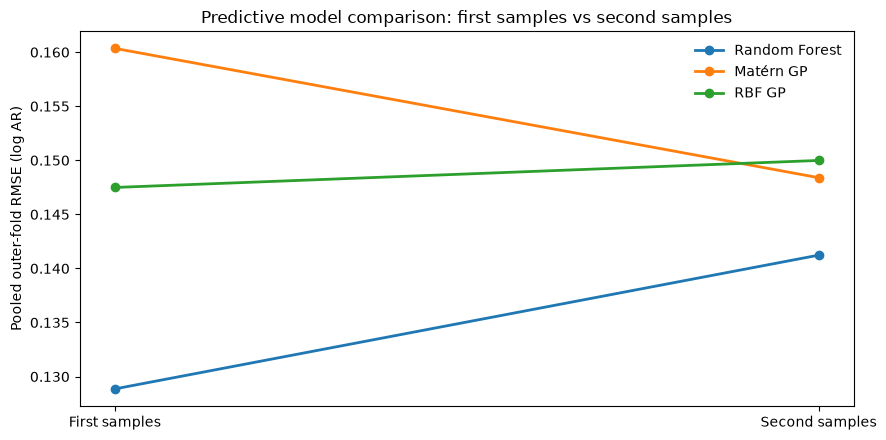

C:\Users\bribi\AppData\Local\Temp\ipykernel_29800\2588530232.py:336: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


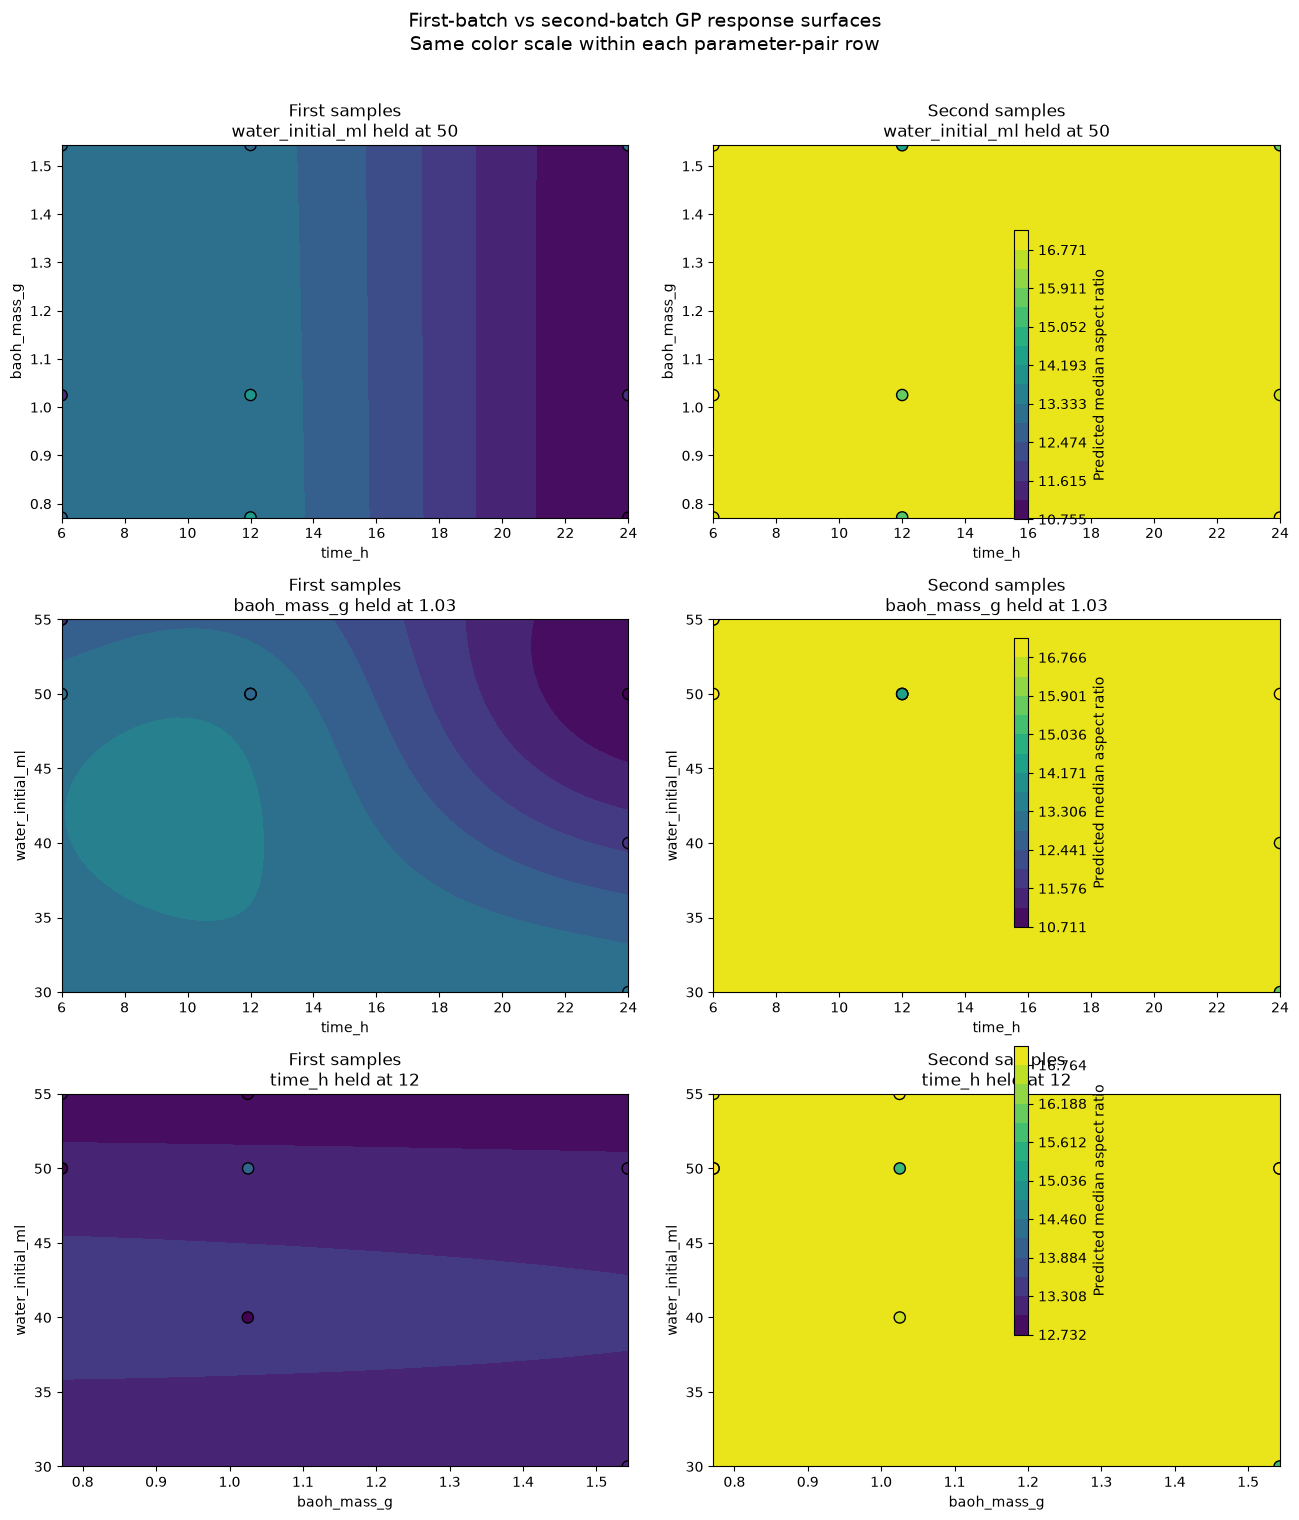

Split-specific proposed experiments (predictions, not measured outcomes):


,Dataset,Strategy,Pick,time_h,baoh_mass_g,water_initial_ml,Predicted mean AR,Predicted SD AR,Pool index
0,First samples,P1 UCB + min-distance,1,10.0,0.60,28.0,13.240,1.554,26146
1,First samples,P1 UCB + min-distance,2,10.0,0.95,27.0,13.218,1.562,27230
2,First samples,P1 UCB + min-distance,3,10.0,1.30,27.0,13.217,1.561,28315
3,First samples,P1 UCB + min-distance,4,10.0,1.66,27.0,13.214,1.561,29431
4,First samples,P2 Kriging believer — UCB,1,10.0,0.60,28.0,13.240,1.554,26146
...,...,...,...,...,...,...,...,...,...
115,Second samples,P3 q-NEI,4,8.0,0.65,25.0,17.161,0.637,17556
116,Second samples,Maximum entropy,1,24.0,2.00,25.0,17.004,0.651,91469
117,Second samples,Maximum entropy,2,4.0,2.00,25.0,17.235,0.656,4340
118,Second samples,Maximum entropy,3,17.0,0.60,25.0,17.003,0.645,56636



Recipe overlap between strategies — First samples


,P1 UCB + min-distance,P2 Kriging believer — UCB,P2 Constant liar mean — UCB,P2 Constant liar low — UCB,P1 EI + min-distance,P2 Kriging believer — EI,P2 Constant liar mean — EI,P2 Constant liar low — EI,P1 PI + min-distance,P2 Kriging believer — PI,P2 Constant liar mean — PI,P2 Constant liar low — PI,P3 q-EI,P3 q-NEI,Maximum entropy
P1 UCB + min-distance,4,1,1,1,0,0,0,0,0,0,0,0,0,0,0
P2 Kriging believer — UCB,1,4,1,1,0,1,1,0,0,0,0,1,0,0,0
P2 Constant liar mean — UCB,1,1,4,1,0,0,0,0,0,0,0,0,0,0,0
P2 Constant liar low — UCB,1,1,1,4,0,0,0,1,0,0,0,0,0,0,0
P1 EI + min-distance,0,0,0,0,4,1,1,1,0,0,0,0,0,0,0
P2 Kriging believer — EI,0,1,0,0,1,4,1,1,0,0,0,0,0,0,0
P2 Constant liar mean — EI,0,1,0,0,1,1,4,1,0,0,0,1,0,0,0
P2 Constant liar low — EI,0,0,0,1,1,1,1,4,0,0,0,0,0,0,0
P1 PI + min-distance,0,0,0,0,0,0,0,0,4,1,1,1,0,0,0
P2 Kriging believer — PI,0,0,0,0,0,0,0,0,1,4,1,1,0,0,0



Recipe overlap between strategies — Second samples


,P1 UCB + min-distance,P2 Kriging believer — UCB,P2 Constant liar mean — UCB,P2 Constant liar low — UCB,P1 EI + min-distance,P2 Kriging believer — EI,P2 Constant liar mean — EI,P2 Constant liar low — EI,P1 PI + min-distance,P2 Kriging believer — PI,P2 Constant liar mean — PI,P2 Constant liar low — PI,P3 q-EI,P3 q-NEI,Maximum entropy
P1 UCB + min-distance,4,2,2,1,0,2,2,1,0,0,0,1,0,1,1
P2 Kriging believer — UCB,2,4,2,2,0,2,2,1,0,0,0,1,0,1,1
P2 Constant liar mean — UCB,2,2,4,1,0,2,2,2,0,0,0,2,0,1,2
P2 Constant liar low — UCB,1,2,1,4,0,1,1,1,0,0,0,1,0,0,2
P1 EI + min-distance,0,0,0,0,4,1,1,1,1,1,1,1,1,0,0
P2 Kriging believer — EI,2,2,2,1,1,4,4,2,1,2,2,2,2,1,1
P2 Constant liar mean — EI,2,2,2,1,1,4,4,2,1,2,2,2,2,1,1
P2 Constant liar low — EI,1,1,2,1,1,2,2,4,1,1,1,4,1,1,1
P1 PI + min-distance,0,0,0,0,1,1,1,1,4,1,1,1,1,0,0
P2 Kriging believer — PI,0,0,0,0,1,2,2,1,1,4,3,1,2,0,0


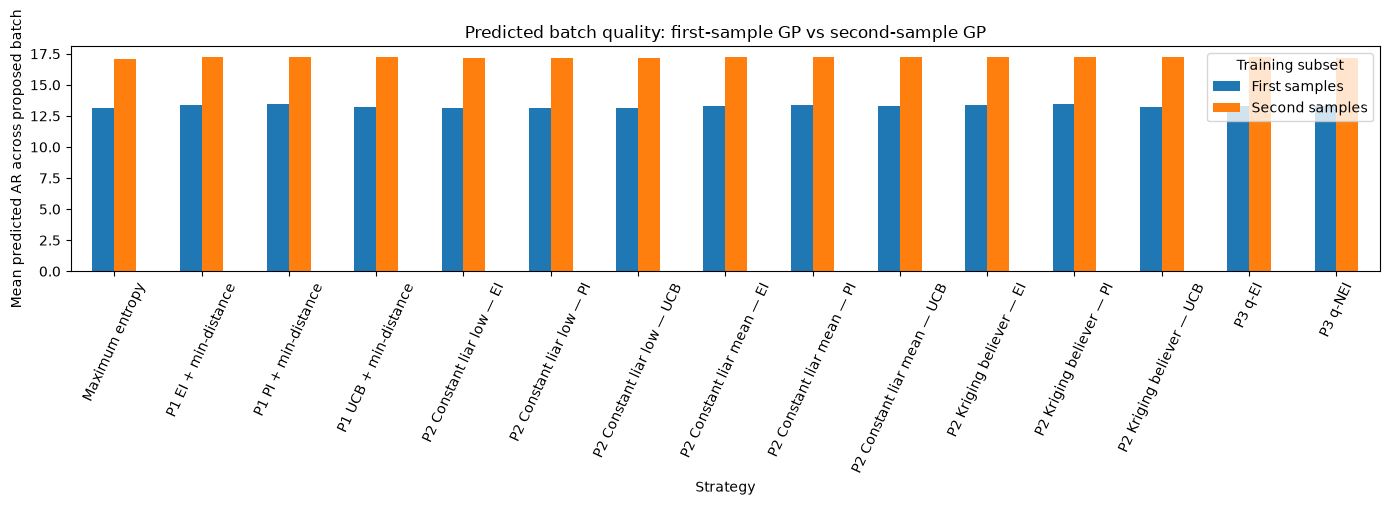

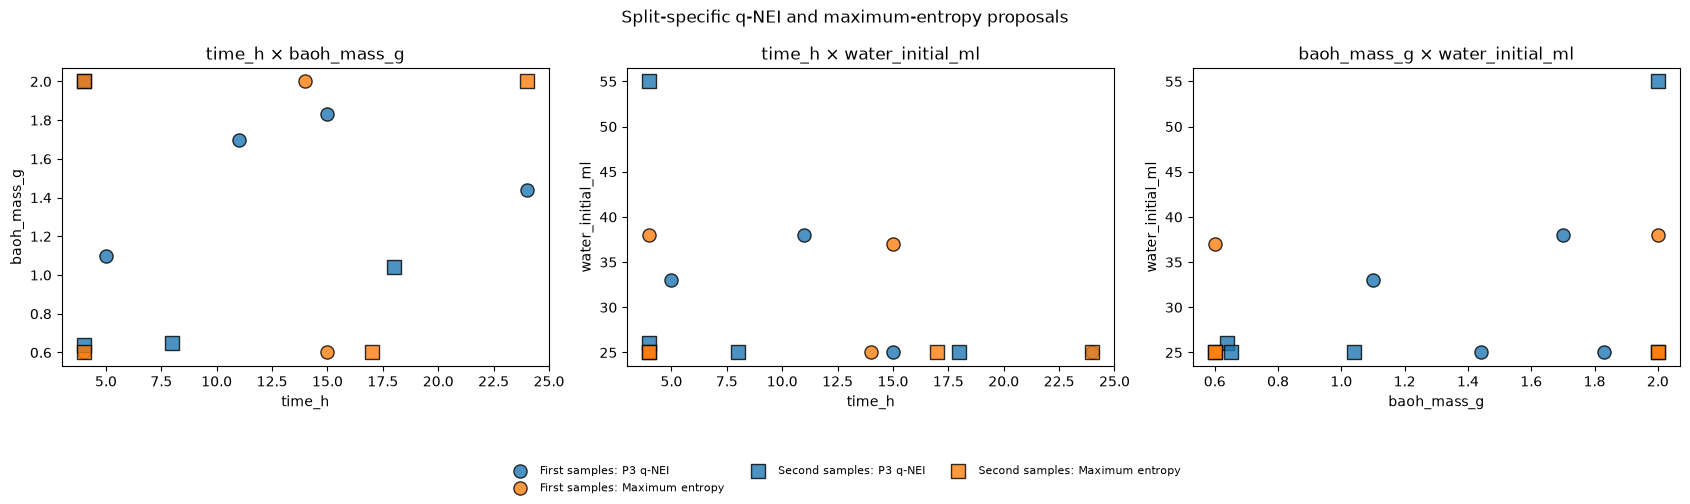


Important: do not select the next laboratory batch simply because one split predicts a larger AR. The first/second split comparison is a sensitivity analysis of model learning. The final experimental decision should use the full dataset, the purity gate, and the agreed batch strategy.


In [21]:
# ---------------------------------------------------------------------------
# B.1 Define the first and second observation sets for every recipe
# ---------------------------------------------------------------------------
# The paired_summary table was built by sorting each recipe's observations
# by numeric batch_id. Its saved row indices point back to df.
#
# Each split has one observation per recipe. We deliberately do not average
# first and second observations here: the purpose is to compare the two
# learned response surfaces independently.

first_indices = paired_summary["first_index"].astype(int).to_list()
second_indices = paired_summary["second_index"].astype(int).to_list()

first_sample_df = df.loc[first_indices].copy().sort_values("recipe_id").reset_index(drop=True)
second_sample_df = df.loc[second_indices].copy().sort_values("recipe_id").reset_index(drop=True)

assert first_sample_df["recipe_id"].is_unique
assert second_sample_df["recipe_id"].is_unique
assert set(first_sample_df["recipe_id"]) == set(second_sample_df["recipe_id"])

print(f"First-batch training set:  {len(first_sample_df)} recipe observations")
print(f"Second-batch training set: {len(second_sample_df)} recipe observations")
display(pd.DataFrame({
    "recipe_id": first_sample_df["recipe_id"].to_numpy(),
    "first batch": first_sample_df["batch_id"].to_numpy(),
    "first AR": first_sample_df[TARGET].to_numpy(),
    "second batch": second_sample_df["batch_id"].to_numpy(),
    "second AR": second_sample_df[TARGET].to_numpy(),
}).round(4))

# ---------------------------------------------------------------------------
# B.2 Fit one operational GP to each split
# ---------------------------------------------------------------------------
# We keep the same custom Matérn-5/2 GP implementation used by the BO
# workflow, including the oven-run random effect. The response is log(AR)
# because the raw AR distribution is right-skewed.
#
# Each split gets its own target mean/SD and its own fitted hyperparameters.
# This is necessary because the purpose is to see how the fitted model
# changes between the two data subsets.

SPLIT_GP_RESTARTS = 25

def _fit_split_state(sample_df, split_name, seed_offset=0):
    X_raw_split = sample_df[OPT_VARS].to_numpy(dtype=float)
    X_split = to_model(X_raw_split)

    y_log_raw = np.log(sample_df[TARGET].to_numpy(dtype=float))
    y_mean_split = float(y_log_raw.mean())
    y_sd_split = float(y_log_raw.std(ddof=0))
    if y_sd_split < 1e-8:
        y_sd_split = 1.0
    y_split = (y_log_raw - y_mean_split) / y_sd_split

    # Preserve shared oven-run offsets within this subset.
    batch_split = pd.factorize(sample_df["batch_id"])[0]
    feasible_split = (
        sample_df[PURITY_COL].to_numpy(dtype=float) >= PURITY_MIN
    )

    H_split = fit_gp(
        X_split, y_split, batch_split,
        n_restarts=SPLIT_GP_RESTARTS,
        null=False,
        seed=SEED + seed_offset
    )

    # There is exactly one observation per recipe in each split.
    # Thus each row here is also one distinct recipe location.
    mu_at_training, _ = posterior(
        H_split, X_split, y_split, batch_split, X_split
    )
    best_f_split = float(np.max(mu_at_training[feasible_split]))

    mu_candidates, var_candidates = posterior(
        H_split, X_split, y_split, batch_split, X_pool
    )

    return {
        "name": split_name,
        "sample_df": sample_df.copy(),
        "X_raw": X_raw_split,
        "X": X_split,
        "y": y_split,
        "y_log_raw": y_log_raw,
        "y_mean": y_mean_split,
        "y_sd": y_sd_split,
        "batch": batch_split,
        "feasible": feasible_split,
        "H": H_split,
        "best_f": best_f_split,
        "mu_pool": mu_candidates,
        "var_pool": var_candidates,
        "sd_pool": np.sqrt(var_candidates),
    }

split_states = {
    "First samples": _fit_split_state(first_sample_df, "First samples", 100),
    "Second samples": _fit_split_state(second_sample_df, "Second samples", 200),
}

# Compare learned hyperparameters and variance components.
split_hyper_rows = []
for split_name, state in split_states.items():
    Hs = state["H"]
    input_names = OPT_VARS + (["hto"] if USE_HTO_IN_MODEL else [])
    split_hyper_rows.append({
        "Dataset": split_name,
        "n recipes": len(state["sample_df"]),
        "amp² (recipe)": Hs["amp2"],
        "sb² (oven batch)": Hs["sb2"],
        "sn² (residual)": Hs["sn2"],
        "lengthscales": {
            name: round(float(value), 3)
            for name, value in zip(input_names, Hs["ls"])
        },
        "negative log marginal likelihood": Hs["nll"],
        "predicted incumbent (median AR)": (
            np.exp(state["best_f"] * state["y_sd"] + state["y_mean"])
        )
    })
split_hyper_summary = pd.DataFrame(split_hyper_rows).set_index("Dataset")
print("Split-specific GP fits:")
display(split_hyper_summary.round(4))

# ---------------------------------------------------------------------------
# B.2b Re-run the shared nested CV benchmark separately on each split
# ---------------------------------------------------------------------------
# The earlier full-data benchmark tested RF, Matérn and RBF using common
# nested GroupKFold partitions. Here we repeat that model-family comparison
# on the first-only and second-only datasets.
#
# Because both subsets contain the same recipe IDs in the same sorted order,
# we create the split-specific folds ONCE and reuse them for every model and
# both subsets. Each split has one observation per recipe, so grouping by
# recipe still protects the validation design and makes the two benchmarks
# directly comparable.
#
# These scikit-learn models are predictive benchmarks. The operational BO
# batches below still use the custom Matérn GP because it explicitly models
# oven-run random effects and supports fantasy/joint-posterior batch selection.

from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_first_cv = first_sample_df[OPT_VARS].astype(float).reset_index(drop=True)
X_second_cv = second_sample_df[OPT_VARS].astype(float).reset_index(drop=True)
y_first_cv = np.log(first_sample_df[TARGET].astype(float)).reset_index(drop=True)
y_second_cv = np.log(second_sample_df[TARGET].astype(float)).reset_index(drop=True)
groups_first_cv = first_sample_df["recipe_id"].reset_index(drop=True)
groups_second_cv = second_sample_df["recipe_id"].reset_index(drop=True)

assert groups_first_cv.equals(groups_second_cv), (
    "First and second split rows must be in the same recipe order "
    "to reuse the exact same CV folds."
)

SPLIT_OUTER_FOLDS = 3
SPLIT_INNER_FOLDS = 3
split_outer_cv = GroupKFold(n_splits=SPLIT_OUTER_FOLDS)
split_cv_splits = list(
    split_outer_cv.split(X_first_cv, y_first_cv, groups_first_cv)
)
split_inner_cv_splits = []
for train_idx, test_idx in split_cv_splits:
    inner = GroupKFold(n_splits=SPLIT_INNER_FOLDS)
    split_inner_cv_splits.append(list(
        inner.split(
            X_first_cv.iloc[train_idx],
            y_first_cv.iloc[train_idx],
            groups_first_cv.iloc[train_idx]
        )
    ))

split_cv_data = {
    "First samples": (X_first_cv, y_first_cv),
    "Second samples": (X_second_cv, y_second_cv)
}
split_cv_predictions = {}
split_cv_searches = {}
split_cv_fold_results = {}
split_cv_rows = []

for split_name, (X_subset, y_subset) in split_cv_data.items():
    split_cv_predictions[split_name] = {}
    split_cv_searches[split_name] = {}
    split_cv_fold_results[split_name] = {}

    for model_name, (estimator, param_grid) in model_specs.items():
        oof = np.full(len(y_subset), np.nan)
        searches = []
        fold_rows = []

        for fold_no, (train_idx, test_idx) in enumerate(split_cv_splits, start=1):
            search = GridSearchCV(
                estimator=estimator,
                param_grid=param_grid,
                scoring=selection_scoring,
                cv=split_inner_cv_splits[fold_no - 1],
                refit=True,
                return_train_score=True,
                n_jobs=-1,
                error_score="raise"
            )
            search.fit(X_subset.iloc[train_idx], y_subset.iloc[train_idx])
            prediction = search.predict(X_subset.iloc[test_idx])
            oof[test_idx] = prediction
            searches.append(search)
            fold_rows.append({
                "Fold": fold_no,
                "Inner CV RMSE": -search.best_score_,
                "Held-out RMSE": np.sqrt(mean_squared_error(
                    y_subset.iloc[test_idx], prediction
                )),
                "Held-out MAE": mean_absolute_error(
                    y_subset.iloc[test_idx], prediction
                ),
                "Best parameters": search.best_params_
            })

        assert np.isfinite(oof).all(), (
            f"Missing split-specific OOF predictions: {split_name}, {model_name}"
        )
        split_cv_predictions[split_name][model_name] = oof
        split_cv_searches[split_name][model_name] = searches
        split_cv_fold_results[split_name][model_name] = pd.DataFrame(fold_rows)

        split_cv_rows.append({
            "Dataset": split_name,
            "Model": model_name,
            "OOF RMSE (log AR)": np.sqrt(np.mean((oof - y_subset.to_numpy()) ** 2)),
            "OOF MAE (log AR)": np.mean(np.abs(oof - y_subset.to_numpy()))
        })

split_cv_summary = pd.DataFrame(split_cv_rows).sort_values(
    ["Dataset", "OOF RMSE (log AR)"]
).reset_index(drop=True)

print("Nested CV comparison for first-only and second-only data:")
display(split_cv_summary.round(4))

for split_name in split_cv_fold_results:
    for model_name, fold_table in split_cv_fold_results[split_name].items():
        print(f"\n{split_name} — {model_name}: fold-specific hyperparameters")
        display(fold_table.round(4))

# Visual comparison: lower OOF RMSE is better, but only compare models within
# the same split and interpret differences cautiously with just nine recipes.
fig, ax = plt.subplots(figsize=(9, 4.5))
for model_name in model_specs:
    view = split_cv_summary[split_cv_summary["Model"] == model_name]
    ax.plot(
        view["Dataset"], view["OOF RMSE (log AR)"],
        marker="o", linewidth=2, label=model_name
    )
ax.set_ylabel("Pooled outer-fold RMSE (log AR)")
ax.set_title("Predictive model comparison: first samples vs second samples")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# B.3 Side-by-side response surfaces for all three parameter pairs
# ---------------------------------------------------------------------------
# The third input is fixed at its full-dataset median for each 2-D slice.
# Within each row, first/second surfaces share the same contour limits.
# This avoids misleading visual differences caused by independent color
# scaling. Dots show the observations used to fit the corresponding GP.

parameter_pairs = [(0, 1), (0, 2), (1, 2)]
slice_values = df[OPT_VARS].median().to_dict()

# Precompute predictions so each row can share a common color scale.
surface_cache = {}
for pair in parameter_pairs:
    a, b = pair
    remaining = next(i for i in range(len(OPT_VARS)) if i not in pair)
    x_grid = np.linspace(df[OPT_VARS[a]].min(), df[OPT_VARS[a]].max(), 55)
    y_grid = np.linspace(df[OPT_VARS[b]].min(), df[OPT_VARS[b]].max(), 55)
    XX, YY = np.meshgrid(x_grid, y_grid)
    raw_grid = np.tile(
        np.array([slice_values[v] for v in OPT_VARS], dtype=float),
        (XX.size, 1)
    )
    raw_grid[:, a] = XX.ravel()
    raw_grid[:, b] = YY.ravel()
    X_grid = to_model(raw_grid)

    for split_name, state in split_states.items():
        mu_grid, _ = posterior(
            state["H"], state["X"], state["y"], state["batch"], X_grid
        )
        median_ar_grid = np.exp(
            mu_grid * state["y_sd"] + state["y_mean"]
        ).reshape(XX.shape)
        surface_cache[(pair, split_name)] = (
            XX, YY, median_ar_grid, remaining
        )

fig, axes = plt.subplots(3, 2, figsize=(13, 15))
for row_no, pair in enumerate(parameter_pairs):
    all_values = np.concatenate([
        surface_cache[(pair, split_name)][2].ravel()
        for split_name in split_states
    ])
    vmin, vmax = float(all_values.min()), float(all_values.max())
    levels = np.linspace(vmin, vmax, 16)

    for col_no, split_name in enumerate(split_states):
        ax = axes[row_no, col_no]
        XX, YY, ZZ, remaining = surface_cache[(pair, split_name)]
        contour = ax.contourf(
            XX, YY, ZZ, levels=levels, cmap="viridis", vmin=vmin, vmax=vmax
        )
        sample_df = split_states[split_name]["sample_df"]
        scatter = ax.scatter(
            sample_df[OPT_VARS[pair[0]]],
            sample_df[OPT_VARS[pair[1]]],
            c=sample_df[TARGET], cmap="viridis",
            vmin=vmin, vmax=vmax,
            edgecolor="black", s=65
        )
        ax.set_xlabel(OPT_VARS[pair[0]])
        ax.set_ylabel(OPT_VARS[pair[1]])
        ax.set_title(
            f"{split_name}\n{OPT_VARS[remaining]} held at {slice_values[OPT_VARS[remaining]]:.3g}"
        )
    fig.colorbar(contour, ax=axes[row_no, :].tolist(),
                 label="Predicted median aspect ratio", shrink=0.85)

fig.suptitle(
    "First-batch vs second-batch GP response surfaces\n"
    "Same color scale within each parameter-pair row",
    y=1.01, fontsize=14
)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# B.4 Generate batch proposals independently for each split-specific GP
# ---------------------------------------------------------------------------
# Every split uses the same candidate pool, Q, D_MIN, KAPPA and XI.
# Only the fitted model and its incumbent are changed.
#
# Prong 1: acquisition ranking + minimum-distance rule.
# Prong 2: sequential fantasy updates (KB, CL-mean, CL-low).
# Prong 3: greedy joint Monte-Carlo q-EI and q-NEI.
# Extra: maximum entropy.
#
# q-EI/q-NEI use a deliberately smaller shortlist and MC count here than
# the full-data comparison, to keep the two additional runs practical.

def _split_acquisition(acq_name, mu, sd, best_f):
    if acq_name == "UCB":
        return acq_ucb(mu, sd, best_f)
    if acq_name == "EI":
        return acq_ei(mu, sd, best_f)
    if acq_name == "PI":
        return acq_pi(mu, sd, best_f)
    raise ValueError(acq_name)

def _split_sequential_batch(state, strategy, acq_name, q=Q):
    X_aug = state["X"].copy()
    y_aug = state["y"].copy()
    b_aug = state["batch"].copy()
    chosen = []

    for _ in range(q):
        mu, var = posterior(
            state["H"], X_aug, y_aug, b_aug, X_pool
        )
        scores = _split_acquisition(
            acq_name, mu, np.sqrt(var), state["best_f"]
        )
        scores[chosen] = -np.inf
        candidate_idx = int(np.argmax(scores))
        chosen.append(candidate_idx)

        if strategy == "KB":
            fantasy_value = mu[candidate_idx]
        elif strategy == "CL_mean":
            fantasy_value = float(np.mean(state["y"]))
        elif strategy == "CL_low":
            fantasy_value = float(np.min(state["y"]))
        else:
            raise ValueError(strategy)

        X_aug = np.vstack([X_aug, X_pool[candidate_idx]])
        y_aug = np.append(y_aug, fantasy_value)
        b_aug = np.append(b_aug, b_aug.max() + 1)

    return np.asarray(chosen, dtype=int)

def _split_joint_batch(state, noisy=True, q=Q, n_mc=512,
                       short_top=200, short_random=300, seed=SEED):
    """Greedy joint q-EI/q-NEI on a compact common shortlist."""
    ei = acq_ei(
        state["mu_pool"], state["sd_pool"], state["best_f"]
    )
    top = np.argsort(-ei)[:min(short_top, len(X_pool))]
    remaining = np.setdiff1d(np.arange(len(X_pool)), top)
    rng = np.random.default_rng(seed)
    random_part = rng.choice(
        remaining, size=min(short_random, len(remaining)), replace=False
    )
    shortlist = np.concatenate([top, random_part])

    # Draw joint latent-function samples at training recipes + shortlist.
    X_joint = np.vstack([state["X"], X_pool[shortlist]])
    mu_joint, cov_joint = posterior(
        state["H"], state["X"], state["y"], state["batch"],
        X_joint, full_cov=True
    )
    L_joint = safe_cholesky(cov_joint)
    Z = rng.standard_normal((len(X_joint), n_mc))
    F = mu_joint[:, None] + L_joint @ Z

    n_train = len(state["X"])
    if noisy:
        incumbent_samples_local = F[:n_train][state["feasible"]].max(axis=0)
    else:
        incumbent_samples_local = np.full(
            n_mc, np.max(state["y"][state["feasible"]])
        )

    candidate_samples = F[n_train:]
    best_in_batch = np.full(n_mc, -np.inf)
    selected_local = []

    for _ in range(q):
        current_best = np.maximum(best_in_batch[None, :], candidate_samples)
        gain = np.maximum(
            current_best - incumbent_samples_local[None, :], 0
        ).mean(axis=1)
        if selected_local:
            gain[selected_local] = -np.inf
        chosen_local = int(np.argmax(gain))
        selected_local.append(chosen_local)
        best_in_batch = current_best[chosen_local]

    return shortlist[np.asarray(selected_local, dtype=int)]

def _split_entropy_batch(state, q=Q):
    X_aug = state["X"].copy()
    y_aug = state["y"].copy()
    b_aug = state["batch"].copy()
    chosen = []
    for _ in range(q):
        _, variance = posterior(
            state["H"], X_aug, y_aug, b_aug, X_pool
        )
        variance[chosen] = -np.inf
        j = int(np.argmax(variance))
        chosen.append(j)
        X_aug = np.vstack([X_aug, X_pool[j]])
        y_aug = np.append(y_aug, 0.0)
        b_aug = np.append(b_aug, b_aug.max() + 1)
    return np.asarray(chosen, dtype=int)

split_batches = {}
split_batch_records = []

for split_no, (split_name, state) in enumerate(split_states.items()):
    methods = {}

    # Prong 1 and 2: same acquisition functions and fantasy variants.
    for acq_name in ["UCB", "EI", "PI"]:
        scores = _split_acquisition(
            acq_name, state["mu_pool"], state["sd_pool"], state["best_f"]
        )
        methods[f"P1 {acq_name} + min-distance"] = min_distance_batch(
            scores, U_pool, Q, D_MIN
        )

        for fantasy in ["KB", "CL_mean", "CL_low"]:
            label = {
                "KB": "Kriging believer",
                "CL_mean": "Constant liar mean",
                "CL_low": "Constant liar low"
            }[fantasy]
            methods[f"P2 {label} — {acq_name}"] = _split_sequential_batch(
                state, fantasy, acq_name, Q
            )

    # Prong 3 and exploration benchmark.
    methods["P3 q-EI"] = _split_joint_batch(
        state, noisy=False, seed=SEED + split_no * 10
    )
    methods["P3 q-NEI"] = _split_joint_batch(
        state, noisy=True, seed=SEED + split_no * 10
    )
    methods["Maximum entropy"] = _split_entropy_batch(state, Q)

    split_batches[split_name] = methods

    # Store the proposed recipes and split-specific posterior predictions.
    for method_name, indices in methods.items():
        for rank, candidate_idx in enumerate(indices, start=1):
            mu_std = state["mu_pool"][candidate_idx]
            var_std = state["var_pool"][candidate_idx]
            mu_log = mu_std * state["y_sd"] + state["y_mean"]
            var_log = var_std * (state["y_sd"] ** 2)
            # Lognormal moments: expected AR and predictive SD in AR units.
            expected_ar = np.exp(mu_log + 0.5 * var_log)
            sd_ar = expected_ar * np.sqrt(np.expm1(np.clip(var_log, 0.0, 20.0)))
            split_batch_records.append({
                "Dataset": split_name,
                "Strategy": method_name,
                "Pick": rank,
                **{
                    variable: float(pool_raw[candidate_idx, j])
                    for j, variable in enumerate(OPT_VARS)
                },
                "Predicted mean AR": float(expected_ar),
                "Predicted SD AR": float(sd_ar),
                "Pool index": int(candidate_idx)
            })

split_proposals = pd.DataFrame(split_batch_records)
print("Split-specific proposed experiments (predictions, not measured outcomes):")
display(split_proposals.round(3))

# ---------------------------------------------------------------------------
# B.5 Compare how the proposed batches differ between first and second data
# ---------------------------------------------------------------------------
# The overlap matrix tells us whether two strategies choose the same recipes.
# The bar chart compares the predicted mean AR of each proposed batch.
# These are diagnostic comparisons only: the split-specific GPs were trained
# on different observed values and therefore need not agree.

for split_name, methods in split_batches.items():
    method_names = list(methods)
    overlap_split = pd.DataFrame(
        [
            [len(set(methods[a]) & set(methods[b])) for b in method_names]
            for a in method_names
        ],
        index=method_names, columns=method_names
    )
    print(f"\nRecipe overlap between strategies — {split_name}")
    display(overlap_split)

fig, ax = plt.subplots(figsize=(14, 5))
batch_mean_predictions = (
    split_proposals.groupby(["Strategy", "Dataset"])["Predicted mean AR"]
    .mean().unstack("Dataset")
)
batch_mean_predictions.plot(kind="bar", ax=ax)
ax.set_ylabel("Mean predicted AR across proposed batch")
ax.set_title("Predicted batch quality: first-sample GP vs second-sample GP")
ax.tick_params(axis="x", rotation=65)
ax.legend(title="Training subset")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# B.6 Plot proposed candidate locations for the two independently fitted GPs
# ---------------------------------------------------------------------------
# To keep the plot readable, show the q-NEI and maximum-entropy proposals,
# which represent exploitation under observation noise and pure exploration.
# The full table above contains all acquisition/fantasy strategies.

focus_methods = ["P3 q-NEI", "Maximum entropy"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
pair_labels = [(0, 1), (0, 2), (1, 2)]
split_markers = {"First samples": "o", "Second samples": "s"}
method_colors = {"P3 q-NEI": "tab:blue", "Maximum entropy": "tab:orange"}

for ax, (a, b) in zip(axes, pair_labels):
    for split_name, methods in split_batches.items():
        for method_name in focus_methods:
            indices = methods[method_name]
            ax.scatter(
                pool_raw[indices, a], pool_raw[indices, b],
                marker=split_markers[split_name],
                color=method_colors[method_name],
                edgecolor="black", s=90, alpha=0.8,
                label=f"{split_name}: {method_name}"
            )
    ax.set_xlabel(OPT_VARS[a])
    ax.set_ylabel(OPT_VARS[b])
    ax.set_title(f"{OPT_VARS[a]} × {OPT_VARS[b]}")

handles, labels = axes[0].get_legend_handles_labels()
# Remove repeated legend entries while preserving their order.
unique_legend = dict(zip(labels, handles))
fig.legend(
    unique_legend.values(), unique_legend.keys(),
    loc="lower center", ncol=3, fontsize=8, frameon=False
)
fig.suptitle("Split-specific q-NEI and maximum-entropy proposals")
plt.tight_layout(rect=(0, 0.15, 1, 1))
plt.show()

print(
    "\nImportant: do not select the next laboratory batch simply because one "
    "split predicts a larger AR. The first/second split comparison is a "
    "sensitivity analysis of model learning. The final experimental decision "
    "should use the full dataset, the purity gate, and the agreed batch strategy."
)

**The experiments themselves.** For each strategy: the proposed recipes with the GP's prediction (real aspect-ratio units) and the *single-experiment* EI of each (note how a recipe can have a modest individual EI yet belong to a good *batch*).

In [22]:
recs = []
for name, idx in BATCHES.items():
    for rank, j in enumerate(idx, 1):
        recs.append({"strategy": name, "pick": rank,
                     **{v: pool_raw[j, i] for i, v in enumerate(OPT_VARS)},
                     "pred_AR": mu_pool[j] * Y_SD + Y_MEAN, "sd_AR": sd_pool[j] * Y_SD,
                     "EI_single": acq_ei(mu_pool[j:j+1], sd_pool[j:j+1], BEST_F)[0] * Y_SD, "pool_row": j})
proposals = pd.DataFrame(recs)
display(proposals.round(3))

# How much do the strategies agree? (number of identical recipes shared by two batches)
names = list(BATCHES)
overlap = pd.DataFrame([[len(set(BATCHES[a]) & set(BATCHES[b])) for b in names] for a in names], index=names, columns=names)
print("\nNumber of identical recipes shared between batches:")
display(overlap)

,strategy,pick,time_h,baoh_mass_g,water_initial_ml,pred_AR,sd_AR,EI_single,pool_row
0,P1 UCB + min-distance,1,4.0,2.00,25.0,15.090,0.846,0.330,4340
1,P1 UCB + min-distance,2,4.0,2.00,33.0,15.091,0.843,0.330,4348
2,P1 UCB + min-distance,3,4.0,1.65,25.0,15.087,0.845,0.329,3255
3,P1 UCB + min-distance,4,4.0,2.00,41.0,15.091,0.842,0.329,4356
4,P2 Kriging believer — UCB,1,4.0,2.00,25.0,15.090,0.846,0.330,4340
5,P2 Kriging believer — UCB,2,4.0,1.99,25.0,15.089,0.846,0.330,4309
6,P2 Kriging believer — UCB,3,4.0,1.98,25.0,15.089,0.846,0.330,4278
7,P2 Kriging believer — UCB,4,4.0,2.00,55.0,15.089,0.841,0.328,4370
8,P2 Constant liar mean — UCB,1,4.0,2.00,25.0,15.090,0.846,0.330,4340
9,P2 Constant liar mean — UCB,2,4.0,1.99,25.0,15.089,0.846,0.330,4309



Number of identical recipes shared between batches:


,P1 UCB + min-distance,P2 Kriging believer — UCB,P2 Constant liar mean — UCB,P2 Constant liar low — UCB,P1 EI + min-distance,P2 Kriging believer — EI,P2 Constant liar mean — EI,P2 Constant liar low — EI,P1 PI + min-distance,P2 Kriging believer — PI,P2 Constant liar mean — PI,P2 Constant liar low — PI,P3 q-EI,P3 q-NEI,Entropy (max-entropy)
P1 UCB + min-distance,4,1,1,1,4,1,1,1,0,0,0,0,1,1,1
P2 Kriging believer — UCB,1,4,4,1,1,3,4,1,0,0,0,0,3,1,1
P2 Constant liar mean — UCB,1,4,4,1,1,3,4,1,0,0,0,0,3,1,1
P2 Constant liar low — UCB,1,1,1,4,1,1,1,3,0,0,0,2,1,1,1
P1 EI + min-distance,4,1,1,1,4,1,1,1,0,0,0,0,1,1,1
P2 Kriging believer — EI,1,3,3,1,1,4,3,1,0,0,0,0,3,1,1
P2 Constant liar mean — EI,1,4,4,1,1,3,4,1,0,0,0,0,3,1,1
P2 Constant liar low — EI,1,1,1,3,1,1,1,4,0,0,0,2,1,1,1
P1 PI + min-distance,0,0,0,0,0,0,0,0,4,1,1,1,0,0,0
P2 Kriging believer — PI,0,0,0,0,0,0,0,0,1,4,4,1,0,0,0


KeyError: 'P2 Constant liar low — EI'

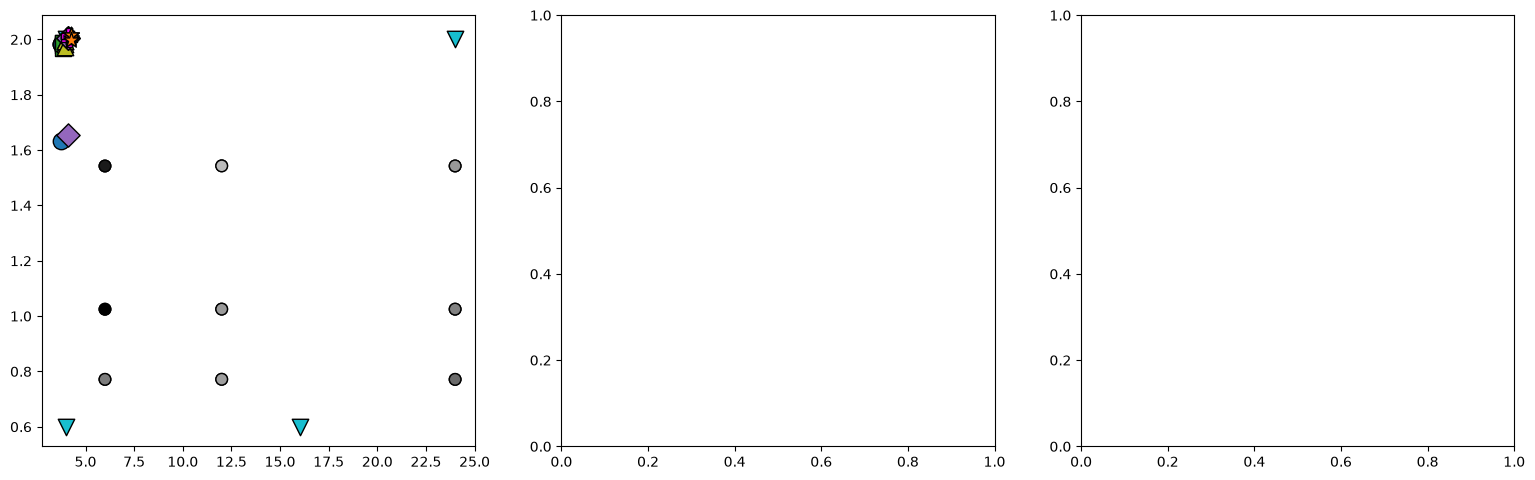

In [25]:
# ---------- Visual comparison: three 2-D projections of the 3-D space ----------
styles = {names[0]: ("tab:blue", "o"), names[1]: ("tab:green", "s"), names[2]: ("tab:olive", "^"), names[3]: ("tab:cyan", "v"),
          names[4]: ("tab:purple", "D"), names[5]: ("magenta", "P"), names[6]: ("tab:orange", "*")}
pairs = [(0, 1), (0, 2), (1, 2)]
fig, axs = plt.subplots(1, 3, figsize=(19, 5.6))
for ax, (a, b) in zip(axs, pairs):
    sc = ax.scatter(df[OPT_VARS[a]], df[OPT_VARS[b]], c=y_raw, cmap="Greys", edgecolor="k", s=70, vmin=y_raw.min(), vmax=y_raw.max(),
                    label="observed (shade = AR)", zorder=2)
    for k, (name, idx) in enumerate(BATCHES.items()):
        col, mk = styles[name]
        jit = (k - 3) * 0.004 * (hi[a] - lo[a]), (k - 3) * 0.004 * (hi[b] - lo[b])   # tiny offset so overlapping picks stay visible
        ax.scatter(pool_raw[idx, a] + jit[0], pool_raw[idx, b] + jit[1], color=col, marker=mk, s=140, edgecolor="k", label=name, zorder=3)
    ax.set_xlabel(OPT_VARS[a]); ax.set_ylabel(OPT_VARS[b]); ax.set_xlim(lo[a]-.03*(hi[a]-lo[a]), hi[a]+.03*(hi[a]-lo[a]))
    ax.set_ylim(lo[b]-.03*(hi[b]-lo[b]), hi[b]+.03*(hi[b]-lo[b]))
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=len(l_), fontsize=9, frameon=False)
fig.suptitle("Proposed batches vs. existing experiments"); plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

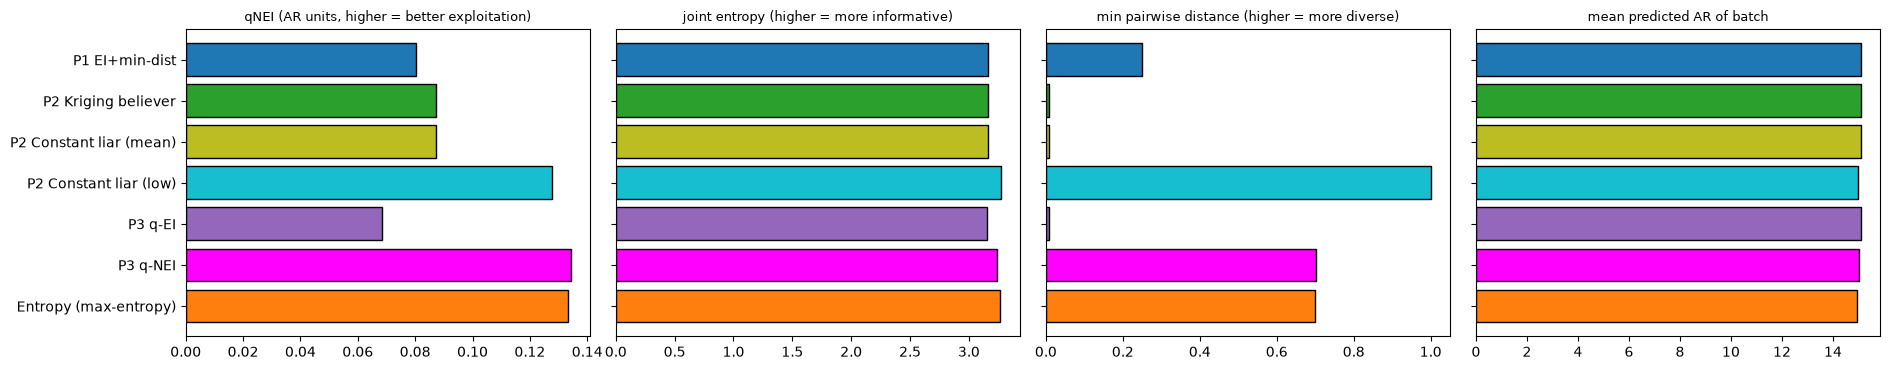

In [ ]:
# ---------- Summary bar charts ----------
fig, axs = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, col, ttl in zip(axs, ["qNEI", "logdet", "min_dist", "mean_mu"],
                        ["qNEI (AR units, higher = better exploitation)", "joint entropy (higher = more informative)",
                         "min pairwise distance (higher = more diverse)", "mean predicted AR of batch"]):
    ax.barh(summary.index, summary[col], color=[styles[n][0] for n in summary.index], edgecolor="k")
    ax.set_title(ttl, fontsize=9); ax.invert_yaxis()
    if col != "qNEI": ax.set_yticklabels([])
plt.tight_layout(); plt.show()

**How to interpret (typical patterns, check against your own table):**
* **P1** is exploitative: high `mean_mu`, but diversity depends entirely on `D_MIN`, which you set by hand.
* **KB** and **CL-mean** behave similarly to each other; **CL-low** spreads the batch more (and may sacrifice predicted AR).
* **q-NEI/q-EI** should have the highest `qNEI` *by construction* (it optimizes it), a good question is *how much higher* than P1/P2. If the margin is tiny, the three prongs are practically equivalent for this problem.
* **Max-entropy** should win `logdet` and `fill` and lose on `mean_mu`: it is the exploration extreme.
* With this much replicate noise, differences of a fraction of an aspect-ratio unit in `qNEI` are **not experimentally distinguishable**.
* `qEI` (fixed incumbent) is ~0 for every batch: the incumbent is the largest *raw* measurement, which includes a lucky oven offset, and nothing in the surface can beat it. That is exactly why the noise-aware q-NEI is the version to use here.
* A batch whose recipes have different times needs **several oven runs**, see Step 11.

## Step 11: Select the experimental batch to synthesize

The choice depends on your objective **and on resources**. Rules of thumb:
* Want the best expected aspect ratio soon → a Prong-3 batch (q-NEI) or Prong 1/2 if they are close in `qNEI`.
* Model still poor (LOO-CV not better than baseline) → lean toward exploration (max-entropy or CL-low).
* A **mixed** batch is also legitimate (e.g., 3 from q-NEI + 1 from max-entropy).

**Oven runs matter for the choice.** Runs share an oven run only if they use the same time (and temperature). A batch that mixes times is really several oven runs, and each oven run brings its own unknown offset. Two practical consequences: (i) if you can only afford one oven run per round, restrict `ALLOWED_TIMES` in Step 1 to one time and re-run from Step 5; (ii) put each recipe in **at least two different oven runs** across rounds (as Round 1 did), otherwise the oven offset and the recipe effect cannot be separated.

Set `CHOSEN` below, and the cell writes a lab-ready CSV with empty result columns for Step 14. `REPLICATES` repeats each recipe (Round 1 ran every recipe twice; given the large scatter, duplicates make each result far more informative, at the cost of a smaller number of *different* recipes per round). The strategy name is saved in a `strategy` column, which Step 17 needs to compare strategies.

In [ ]:
CHOSEN     = "P3 q-NEI"     # one of the keys of BATCHES (printed above)
REPLICATES = 1              # 1 = each recipe once; 2 = every recipe in two different oven runs (like Round 1)

T_CONST    = float(df["temperature_c"].iloc[0]); RINSE_CONST = float(df["water_rinse_ml"].iloc[0])
HTO_CONST  = round(float(df["hto_mass_g"].median()), 4)          # HTO is held fixed at its typical value

sel = BATCHES[CHOSEN]
out = pd.DataFrame(np.repeat(pool_raw[sel], REPLICATES, axis=0), columns=OPT_VARS)
out["replicate"] = np.tile(np.arange(REPLICATES), len(sel))

# ---- assign oven runs: runs share an oven run only if they have the SAME time and the same replicate index ----
# (a second replicate goes into a different oven run on purpose: that is what lets the GP separate oven offsets from recipe effects)
nums = df["batch_id"].str.extract(r"(\d+)")[0].astype(float)
next_b = int(nums.max()) + 1 if nums.notna().any() else 1
keys = out[["time_h", "replicate"]].drop_duplicates().sort_values(["replicate", "time_h"]).reset_index(drop=True)
keys["batch_id"] = [f"B{next_b + i}" for i in range(len(keys))]
out = out.merge(keys, on=["time_h", "replicate"], how="left").sort_values("batch_id", kind="stable").reset_index(drop=True)
out["notes"] = out["batch_id"] + "S" + (out.groupby("batch_id").cumcount() + 1).astype(str)   # same naming as Round 1 (B3S2 ...)

out.insert(0, "run_id", range(int(df.run_id.max()) + 1, int(df.run_id.max()) + 1 + len(out)))
out.insert(1, "round", int(df["round"].max()) + 1)
out.insert(2, "temperature_c", T_CONST); out.insert(4, "hto_mass_g", HTO_CONST); out["water_rinse_ml"] = RINSE_CONST
out["aspect_ratio"] = np.nan; out["purity_pct"] = np.nan          # to be filled after SEM / XRD
out["strategy"] = CHOSEN
out = out[["run_id", "round", "temperature_c", "time_h", "hto_mass_g", "baoh_mass_g", "water_initial_ml", "water_rinse_ml",
           "aspect_ratio", "purity_pct", "notes", "batch_id", "strategy"]]
out.to_csv("proposed_batch_next_round.csv", index=False)
proposals.to_csv("all_proposed_batches_comparison.csv", index=False)
display(out)

n_ovens = out["batch_id"].nunique()
print(f"These {len(out)} runs need {n_ovens} oven run(s) (runs can share an oven run only if they use the same time).")
if n_ovens > REPLICATES:
    print("If you can only do ONE oven run per round, set ALLOWED_TIMES in Step 1 to a single time and re-run from Step 5:")
    print("the strategies then compete on recipes (BaOH, water) at that time, which is also what keeps oven-run effects estimable.")
print("Saved: proposed_batch_next_round.csv (to synthesize) and all_proposed_batches_comparison.csv (for the record)")

,run_id,round,temperature_c,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,water_rinse_ml,aspect_ratio,purity_pct,notes,batch_id,strategy
0,19,2,210.0,4.0,0.1402,2.00,25.0,10.0,NaN,NaN,B7S1,B7,P3 q-NEI
1,20,2,210.0,4.0,0.1402,0.82,55.0,10.0,NaN,NaN,B7S2,B7,P3 q-NEI
2,21,2,210.0,9.0,0.1402,0.70,26.0,10.0,NaN,NaN,B8S1,B8,P3 q-NEI
3,22,2,210.0,18.0,0.1402,1.94,26.0,10.0,NaN,NaN,B9S1,B9,P3 q-NEI


These 4 runs need 3 oven run(s) (runs can share an oven run only if they use the same time).
If you can only do ONE oven run per round, set ALLOWED_TIMES in Step 1 to a single time and re-run from Step 5:
the strategies then compete on recipes (BaOH, water) at that time, which is also what keeps oven-run effects estimable.
Saved: proposed_batch_next_round.csv (to synthesize) and all_proposed_batches_comparison.csv (for the record)


## Step 12: Perform the hydrothermal synthesis (lab)

Run the recipes in `proposed_batch_next_round.csv`. Keep every other condition identical to Round 1 (temperature, HTO mass, rinse, procedure). Record deviations, unexpected observations and failed reactions in `notes`. A failed reaction is *information*: do not silently drop it (write it down and decide how to encode it, e.g. as infeasible).

## Step 13: Characterize (lab)

* **SEM** → needle length/width → aspect ratio (same measuring protocol for every sample; keep per-run values, do not average replicates in the file).
* **XRD** (± Rietveld) → phase purity (`purity_pct`).

Fill `aspect_ratio` and `purity_pct` in the CSV.

## Step 14: Update the experimental dataset

Only **measured** values enter the dataset. The helper below refuses a file that has missing results or columns that look like predictions/fantasies. It deliberately works on the *raw* table (`df_raw`) and lets Step 2 recompute `recipe_id`.

In [ ]:
def append_new_results(df_old_raw, filled_csv, save_as):
    """Append the measured results of a finished round to the experimental dataset."""
    new = pd.read_csv(filled_csv)
    required = OPT_VARS + [TARGET, PURITY_COL]
    assert new[required].notna().all().all(), "Some runs have no measured aspect ratio / purity yet (or a missing parameter)."
    suspicious = [c for c in new.columns if any(t in c.lower() for t in ("fantasy", "pred", "mu_", "sd_"))]
    assert not suspicious, f"Columns that look like predictions/fantasies must not be saved as data: {suspicious}"
    merged = pd.concat([df_old_raw, new], ignore_index=True)
    merged.to_csv(save_as, index=False)
    print(f"Saved {save_as}: {len(df_old_raw)} old + {len(new)} new runs")
    return merged

# Usage after the lab work (left commented so this notebook runs end-to-end):
# df_raw_updated = append_new_results(df_raw, "proposed_batch_next_round.csv", "Experiment_Results_Rd2.csv")

## Step 15: Retrain the GP

Set `CSV_PATH = "Experiment_Results_Rd2.csv"` in Step 1 and re-run from Step 2 downward. Steps 2–5 rebuild the recipes, refit the GP on the enlarged dataset and regenerate the candidate pool; the new μ(x), σ(x) become the common starting model of the next iteration.

## Step 16: Repeat the batch-selection / experiment cycle

Re-run Steps 6–11 with the updated GP. Because all strategies start from the same data and model each round, differences between rounds' outcomes can be attributed to the **batch-selection strategy**, which is the whole point of the study.

Two practical suggestions for fair comparison across rounds:
* Each round, the proposed batch can come from **different strategies** (e.g., 2 recipes from each of two strategies, labelled in the `strategy` column), so that all strategies are tested under the same lab conditions/time.
* Keep `Q`, bounds, kernel, acquisition and `D_MIN` unchanged between rounds.

## Step 17: Evaluate optimization performance across iterations

Use **measured** outcomes only. The function below summarizes, per round and strategy: number of runs, best purity-acceptable aspect ratio, average, fraction meeting the purity requirement, and a cumulative "best so far" curve; plus the number of experiments needed to reach a target, and reproducibility (replicate std) per recipe. It needs `round` and (for rounds after the first) `strategy` columns; Round 1 is labelled `initial`.

In [ ]:
def evaluate_progress(d, target_ar=None):
    d = d.copy()
    if "strategy" not in d.columns: d["strategy"] = np.nan
    d["strategy"] = d["strategy"].fillna("initial")
    d["feasible"] = d[PURITY_COL] >= PURITY_MIN
    d["AR_feasible"] = d[TARGET].where(d["feasible"])              # NaN if the sample is not pure enough
    per = (d.groupby(["round", "strategy"])
             .agg(n_runs=("run_id", "size"), mean_AR=(TARGET, "mean"),
                  best_AR_feasible=("AR_feasible", "max"), frac_feasible=("feasible", "mean")))
    cum = d.sort_values("run_id")["AR_feasible"].cummax().reset_index(drop=True)
    print("Per round and strategy:"); display(per.round(3))
    best_by_round = d.groupby("round")["AR_feasible"].max().cummax()
    print("Best purity-acceptable aspect ratio so far, by round:"); display(best_by_round.round(3).to_frame("best_so_far"))
    if target_ar is not None:
        hit = np.where(cum.values >= target_ar)[0]
        print(f"Experiments needed to reach AR >= {target_ar}: {hit[0] + 1 if len(hit) else 'not reached yet'}")
    rep_std = d.groupby("recipe_id")[TARGET].std().dropna()
    print(f"Reproducibility: median replicate std = {rep_std.median():.2f} (n recipes with replicates = {len(rep_std)})")
    return per

_ = evaluate_progress(df, target_ar=None)     # with Round 1 only this is a baseline snapshot

Per round and strategy:


C:\Users\bribi\AppData\Local\Temp\ipykernel_28616\2884635045.py:4: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  d["strategy"] = d["strategy"].fillna("initial")


,,n_runs,mean_AR,best_AR_feasible,frac_feasible
round,strategy,,,,
1,initial,18,14.93,21.821,1.0


Best purity-acceptable aspect ratio so far, by round:


,best_so_far
round,
1,21.821


Reproducibility: median replicate std = 2.75 (n recipes with replicates = 9)


## Step 18: Validate the final optimized condition

When a recipe looks best, run **several new independent replicates** and compare with the baseline recipe. With 2–4 replicates per group the statistical power is low, so report the *difference with a confidence interval* (bootstrap) and not only a p-value.

In [ ]:
def compare_to_baseline(d, recipe_id_new, recipe_id_baseline, n_boot=10000, seed=0):
    """Difference in mean aspect ratio (new - baseline) with a bootstrap 95% interval, using ONLY replicates of each recipe.
    Also reports Welch's t-test. Use it on new validation runs (not on the data that selected the recipe)."""
    from scipy.stats import ttest_ind
    a = d.loc[d.recipe_id == recipe_id_new, TARGET].values
    b = d.loc[d.recipe_id == recipe_id_baseline, TARGET].values
    r = np.random.default_rng(seed)
    diffs = [r.choice(a, len(a)).mean() - r.choice(b, len(b)).mean() for _ in range(n_boot)]
    lo_ci, hi_ci = np.percentile(diffs, [2.5, 97.5])
    t = ttest_ind(a, b, equal_var=False)
    print(f"mean(new)={a.mean():.2f} (n={len(a)})  mean(base)={b.mean():.2f} (n={len(b)})  diff={a.mean()-b.mean():.2f}  "
          f"95% bootstrap CI [{lo_ci:.2f}, {hi_ci:.2f}]  Welch p={t.pvalue:.3f}")
# Usage once validation runs exist:  compare_to_baseline(df, recipe_id_new=10, recipe_id_baseline=1)

## Step 19: Drawing conclusions about the batch-selection strategies

Questions the final analysis should answer, with the caveats that apply to this problem:
1. **Does accounting for correlations (joint q-NEI) beat ranking + distance?** Compare experimentally measured best-so-far curves (Step 17), not predicted `qNEI`.
2. **Is sequential fantasy-based selection as good as joint optimization?** In a 3-variable space with q≈4, they often propose very similar batches. Check the overlap matrix in Step 10: if batches share most recipes, no experiment-level difference can emerge.
3. **Is the exploration extreme (max-entropy) worth it?** Look at the reduction in predictive uncertainty and the LOO-CV improvement it gives in the following round.

**Honest limits.** With a handful of rounds, tens of runs and replicate scatter comparable to the effect size, *real-experiment* comparisons between strategies will rarely be statistically conclusive. Two complementary tools if you need stronger evidence: (i) compare strategies *in silico* on a synthetic ground truth drawn from the fitted GP (many repetitions, free of lab cost); (ii) use the diversity/coverage/`qNEI` metrics of Step 10 across several rounds as supporting evidence.